# Effectiveness of thrombolysis and thrombectomy in early (6 hr) arrivals with non-mild stroke: S-learner

**Good outcome = discharge mRS 0-2, or discharge mRS no worse than pre-stroke mRS**

An S-learner ("single learner") is one machine learning model that predicts outcome from patient characteristics *and* the treatment received. Treatment effects are estimated by asking the fitted model a counterfactual question: what would the predicted outcome be for this patient if the treatment variables were changed (here, to "no treatment")? For the estimates to have a causal interpretation the model must include all confounders (factors that affect both outcome and the propensity to be treated), and there must be adequate overlap between treated and untreated patients with similar characteristics.

## Selection criteria

* Arrival within 6 hours of known stroke onset
* Thrombolysis, if given, given within 6 hours of onset
* Thrombectomy, if given, given within 12 hours of onset, and not before thrombolysis
* Stroke type = infarction
* No recorded use of perfusion imaging
* Stroke severity (NIHSS) > 5, or recorded large vessel occlusion (LVO)
* Stroke team carried out at least 10 thrombectomies in the selected data

## Outcome

* Good outcome: discharge mRS 0-2, or discharge mRS <= pre-stroke mRS

## Treatment variables

* Part A: onset-to-thrombolysis and onset-to-thrombectomy times (continuous; 'not given' coded with a sentinel value)
* Part B: treatment arm (modality x early/late)

## Adjustment features

Prior disability, stroke severity, age, congestive heart failure, hypertension, diabetes, atrial fibrillation anticoagulant, any atrial fibrillation diagnosis (existing or new), stroke team, ethnicity.

## Notebook structure

1. **Set-up**: modules, settings, data selection, treatment groups, descriptive statistics, shared modelling functions.
2. **Part A - treatment times as continuous features**: 5-fold cross-validated XGBoost S-learner with hyperparameters tuned by cross-validation; out-of-fold counterfactual predictions for treated patients with thrombolysis and/or thrombectomy removed; benefit by time to treatment (heatmaps, regression, SHAP).
3. **Part B - grouped treatment arms**: as Part A, but treatment represented as a categorical arm; conditional average treatment effect (CATE) for each arm.
4. **Part C - meta-model of benefit**: a model of individual estimated benefit, to see which patient characteristics are associated with larger or smaller benefit.
5. **Part D - sensitivity analysis**: overlap, robustness to analytic choices, and unmeasured confounding.

*Although results are reported by treatment group, each model is fitted to all patients (no treatment, thrombolysis alone, thrombectomy alone, both).*

# Set-up

## Load modules

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap
import statsmodels.api as sm
from IPython.display import display
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, log_loss, r2_score, roc_auc_score
from sklearn.model_selection import (
    KFold, StratifiedKFold, cross_val_predict, cross_validate,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

# Suppress library warnings for cleaner output
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)


## Settings

* `CUTOFF` separates 'early' from 'late' treatment (minutes from onset).
* Treatment not given is coded as `NO_TREATMENT` (99999 minutes). Because this value is far beyond any real treatment time, a tree-based model can separate treated from untreated patients with a single split on the time feature. Setting a time to the sentinel value is how the 'no treatment' counterfactual is created.
* `POS_WEIGHT_FACTOR_*` are the manually chosen class-weight multipliers of the original specification (default XGBoost settings with class weighting). The primary analysis now uses tuned hyperparameters without class weighting; the original specification is kept as a sensitivity scenario (Part D).
* `N_TUNING_TRIALS`, `TUNING_TIMEOUT` and `TUNING_CV` control the Optuna hyperparameter search.

In [2]:
PREFIX = "non_mild_stroke_early_arrival_good_outcome_s_learner"
DATA_PATH = "../data/sam3/cleaned_data.csv"
OUTPUT_DIR = "./output"

MRS_TARGET = 2          # Good outcome: discharge mRS <= MRS_TARGET (or no worse than pre-stroke)
CUTOFF = 270            # Minutes from onset separating early and late treatment
NO_TREATMENT = 99999    # Sentinel time meaning 'treatment not given'

N_SPLITS = 5
RANDOM_STATE = 42

# Original specification: multipliers for scale_pos_weight (neg/pos ratio x factor)
POS_WEIGHT_FACTOR_TIMES = 0.55   # Part A model
POS_WEIGHT_FACTOR_GROUPS = 0.38  # Part B model

# Hyperparameter tuning
N_TUNING_TRIALS = 60      # Optuna trials (TPE sampler, median pruning)
TUNING_TIMEOUT = None     # Optional time limit for the search, in seconds (None = no limit)
TUNING_CV = 3             # Folds used to score each trial

TIME_THROMBOLYSIS = "onset_to_thrombolysis_time"
TIME_THROMBECTOMY = "onset_to_thrombectomy_time"

os.makedirs(OUTPUT_DIR, exist_ok=True)


def output_path(name):
    """Path for a saved output file, using the notebook prefix."""
    return f"{OUTPUT_DIR}/{PREFIX}_{name}"

## Features

Adjustment features are the measured confounders. Stroke team and ethnicity are categorical and are passed to XGBoost as pandas `category` columns (native categorical handling, no one-hot encoding). In Part A the two treatment times are added as features; in Part B they are replaced by a single treatment-arm feature.

In [3]:
ADJUSTMENT_FEATURES = [
    "prior_disability",
    "stroke_severity",
    "age",
    "congestive_heart_failure",
    "hypertension",
    "diabetes",
    "afib_anticoagulant",
    "any_afib_diagnosis",
]
TIME_FEATURES = [TIME_THROMBOLYSIS, TIME_THROMBECTOMY]
CATEGORICAL_FEATURES = ["stroke_team", "ethnicity"]
NUMERIC_FEATURES = ADJUSTMENT_FEATURES + TIME_FEATURES

# Part A: treatment represented by times
X_FIELDS_TIMES = ADJUSTMENT_FEATURES + TIME_FEATURES + CATEGORICAL_FEATURES
# Part B: treatment represented by arm
X_FIELDS_GROUPS = ADJUSTMENT_FEATURES + ["treatment_group"] + CATEGORICAL_FEATURES

## Load and select data

Selection steps, in order:

1. Remove patients with missing discharge mRS (outcome unknown).
2. Keep ischaemic stroke (infarction) only.
3. Keep arrivals within 6 hours of onset.
4. Exclude patients where perfusion imaging was used (often linked to extended-window selection, which would select a different population).
5. Keep non-mild stroke: NIHSS > 5, or LVO recorded.
6. Keep stroke teams with at least 10 thrombectomies, so team effects can be estimated alongside thrombectomy.
7. Code missing treatment times with the sentinel value.
8. Remove records where thrombolysis is recorded after thrombectomy (implausible order).
9. Remove thrombectomy at 12 hours or later, and thrombolysis at 6 hours or later.

In [4]:
data = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Initial data shape: {data.shape}")

# Categorical features: label empty strings and use pandas 'category' dtype
for col in CATEGORICAL_FEATURES:
    data[col] = data[col].replace("", "Empty").astype("category")

# Numeric features: coerce non-numeric entries to NaN (XGBoost handles missing values)
for col in NUMERIC_FEATURES:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# 1-5: outcome known, infarction, arrival < 6 hrs, no perfusion imaging, non-mild stroke
data = data.dropna(subset=["discharge_disability"])
data = data[data["infarction"] == 1]
data = data[data["onset_to_arrival_time"] < 360]
data = data[data["perfusion_imaging_used"] == 0]
data = data[(data["stroke_severity"] > 5) | (data["lvo"] == 1)]

# 6: teams with at least 10 thrombectomies (count of non-missing thrombectomy times)
thrombectomy_counts = data.groupby("stroke_team", observed=False)[TIME_THROMBECTOMY].count()
data = data[data["stroke_team"].isin(thrombectomy_counts[thrombectomy_counts >= 10].index)]

# 7: missing treatment time = treatment not given
data[TIME_FEATURES] = data[TIME_FEATURES].fillna(NO_TREATMENT)

# 8: remove thrombolysis after thrombectomy (when both given)
both_given = (data[TIME_THROMBOLYSIS] < NO_TREATMENT) & (data[TIME_THROMBECTOMY] < NO_TREATMENT)
data = data[~(both_given & (data[TIME_THROMBOLYSIS] > data[TIME_THROMBECTOMY]))]

# 9: time limits for treatment (sentinel values retained)
data = data[(data[TIME_THROMBECTOMY] < 720) | (data[TIME_THROMBECTOMY] == NO_TREATMENT)]
data = data[(data[TIME_THROMBOLYSIS] < 360) | (data[TIME_THROMBOLYSIS] == NO_TREATMENT)]

print(f"Final data shape: {data.shape}\n")

ivt_given = data[TIME_THROMBOLYSIS] != NO_TREATMENT
evt_given = data[TIME_THROMBECTOMY] != NO_TREATMENT
treatment_counts = pd.Series({
    "Thrombectomy (any)": evt_given.sum(),
    "Thrombectomy only": (evt_given & ~ivt_given).sum(),
    "Thrombolysis (any)": ivt_given.sum(),
    "Thrombolysis only": (ivt_given & ~evt_given).sum(),
    "Thrombolysis and thrombectomy": (ivt_given & evt_given).sum(),
    "Neither": (~ivt_given & ~evt_given).sum(),
}, name="patients")
treatment_counts.to_frame()

Initial data shape: (452863, 73)
Final data shape: (74678, 73)



,patients
Thrombectomy (any),8147
Thrombectomy only,2983
Thrombolysis (any),34048
Thrombolysis only,28884
Thrombolysis and thrombectomy,5164
Neither,37647


## Treatment groups

Each patient is assigned to one of eight groups by modality and timing relative to `CUTOFF`. These groups are used for descriptive statistics and as the treatment feature in Part B.

Boundary convention (kept from the original analysis): thrombolysis at exactly `CUTOFF` minutes counts as **early**, thrombectomy at exactly `CUTOFF` minutes counts as **late**. Late thrombolysis with early thrombectomy cannot occur, because thrombolysis after thrombectomy has been excluded.

The column is stored as a categorical with alphabetically ordered categories, so every cross-validation fold uses the same category coding.

In [5]:
TREATMENT_GROUP_ORDER = [
    "neither",
    "early_thrombolysis_only",
    "late_thrombolysis_only",
    "early_thrombectomy_only",
    "late_thrombectomy_only",
    "early_both",
    "early_thrombolysis_late_thrombectomy",
    "late_both",
]


def add_treatment_groups(df, cutoff=CUTOFF):
    """Add a categorical 'treatment_group' column based on modality and early/late timing."""
    ivt, evt = df[TIME_THROMBOLYSIS], df[TIME_THROMBECTOMY]
    ivt_given, evt_given = ivt != NO_TREATMENT, evt != NO_TREATMENT
    ivt_early, ivt_late = ivt_given & (ivt <= cutoff), ivt_given & (ivt > cutoff)
    evt_early, evt_late = evt_given & (evt < cutoff), evt_given & (evt >= cutoff)

    conditions = {
        "early_thrombolysis_only": ivt_early & ~evt_given,
        "late_thrombolysis_only": ivt_late & ~evt_given,
        "early_thrombectomy_only": ~ivt_given & evt_early,
        "late_thrombectomy_only": ~ivt_given & evt_late,
        "early_both": ivt_early & evt_early,
        "early_thrombolysis_late_thrombectomy": ivt_early & evt_late,
        "late_both": ivt_late & evt_late,
    }
    groups = np.select(list(conditions.values()), list(conditions.keys()), default="neither")
    df["treatment_group"] = pd.Categorical(groups, categories=sorted(TREATMENT_GROUP_ORDER))
    return df


data = add_treatment_groups(data)
data["treatment_group"].value_counts().reindex(TREATMENT_GROUP_ORDER).to_frame("patients")

,patients
treatment_group,
neither,37647
early_thrombolysis_only,27695
late_thrombolysis_only,1189
early_thrombectomy_only,1107
late_thrombectomy_only,1876
early_both,2309
early_thrombolysis_late_thrombectomy,2714
late_both,141


## Descriptive statistics by treatment group

Treatment times are summarised for treated patients only (sentinel values are set to missing for this table, so that means and percentiles are not distorted by the 99999 code).

In [6]:
descriptive_data = data[ADJUSTMENT_FEATURES + TIME_FEATURES + ["treatment_group"]].copy()
descriptive_data[TIME_FEATURES] = descriptive_data[TIME_FEATURES].replace(NO_TREATMENT, np.nan)

descriptive_stats = (
    descriptive_data.groupby("treatment_group", observed=False)[ADJUSTMENT_FEATURES + TIME_FEATURES]
    .describe()
    .T
    .reindex(columns=TREATMENT_GROUP_ORDER)
    .round(2)
    .rename_axis(["feature", "statistic"])
    .reset_index()
)
descriptive_stats.to_csv(output_path("descriptive_stats.csv"), index=False)
descriptive_stats

treatment_group,feature,statistic,neither,early_thrombolysis_only,late_thrombolysis_only,early_thrombectomy_only,late_thrombectomy_only,early_both,early_thrombolysis_late_thrombectomy,late_both
0,prior_disability,count,37647.00,27695.00,1189.00,1107.00,1876.00,2309.00,2714.00,141.00
1,prior_disability,mean,1.87,1.00,0.97,0.75,0.63,0.43,0.41,0.45
2,prior_disability,std,1.60,1.31,1.29,0.89,0.85,0.74,0.73,0.70
3,prior_disability,min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,prior_disability,25%,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...
75,onset_to_thrombectomy_time,min,NaN,NaN,NaN,0.00,270.00,81.00,270.00,320.00
76,onset_to_thrombectomy_time,25%,NaN,NaN,NaN,180.00,320.00,182.00,301.00,375.00
77,onset_to_thrombectomy_time,50%,NaN,NaN,NaN,211.00,375.00,215.00,336.00,420.00
78,onset_to_thrombectomy_time,75%,NaN,NaN,NaN,240.00,455.00,243.00,390.00,483.00


## Shared modelling functions

* `good_outcome`: binary outcome (discharge mRS <= target, optionally also counting discharge mRS no worse than pre-stroke mRS as good).
* `split_folds`: stratified k-fold split (stratified on outcome). Every patient appears in exactly one test fold.
* `xgb_factory`: returns a function that builds an XGBoost classifier for a training fold, with optional class weighting.
* `train_and_evaluate`: fits one model per fold and reports out-of-fold AUC, balanced accuracy, observed and predicted positive rate, and mean predicted probability (a basic calibration-in-the-large check).
* `to_log_odds`: converts probabilities to log-odds after clipping to avoid infinite values.
* `tune_xgb`: Optuna (TPE sampler) search over XGBoost hyperparameters, scored by cross-validated log loss, with unpromising trials pruned early (see Part A method notes).

In [7]:
def good_outcome(df, mrs_target=MRS_TARGET, include_no_worse=True):
    """1 if discharge mRS <= target (or, optionally, no worse than pre-stroke mRS), else 0."""
    outcome = df["discharge_disability"] <= mrs_target
    if include_no_worse:
        outcome = outcome | (df["discharge_disability"] <= df["prior_disability"])
    return outcome.astype(int)


def split_folds(X, y, n_splits=N_SPLITS, random_state=RANDOM_STATE):
    """Return a list of (train_X, test_X, train_y, test_y) for stratified k-fold splits."""
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    return [
        (X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx])
        for train_idx, test_idx in skf.split(X, y)
    ]


def xgb_factory(pos_weight_factor=None, **xgb_params):
    """
    Return a function that builds an XGBoost classifier for a training fold.

    If pos_weight_factor is given, scale_pos_weight = (negatives / positives) x factor;
    otherwise no class weighting is used.
    """
    def make_model(train_y):
        weight = 1.0
        if pos_weight_factor is not None:
            positives = train_y.sum()
            weight = (len(train_y) - positives) / positives * pos_weight_factor
        return XGBClassifier(
            enable_categorical=True,
            verbosity=0,
            random_state=RANDOM_STATE,
            eval_metric="logloss",
            scale_pos_weight=weight,
            **xgb_params,
        )
    return make_model


def train_and_evaluate(folds, model_factory):
    """Fit one model per fold; return the models and a table of out-of-fold performance."""
    models, results = [], []
    for split, (train_X, test_X, train_y, test_y) in enumerate(folds, start=1):
        model = model_factory(train_y)
        model.fit(train_X, train_y)
        probabilities = model.predict_proba(test_X)[:, 1]
        predictions = model.predict(test_X)
        models.append(model)
        results.append({
            "split": split,
            "AUC": roc_auc_score(test_y, probabilities),
            "balanced_accuracy": balanced_accuracy_score(test_y, predictions),
            "actual_positive_rate": test_y.mean(),
            "predicted_positive_rate": predictions.mean(),
            "mean_predicted_probability": probabilities.mean(),
        })
    return models, pd.DataFrame(results).set_index("split").round(4)


def to_log_odds(probabilities, eps=1e-9):
    """Convert probabilities to log-odds, clipping to avoid infinite values."""
    p = np.clip(probabilities, eps, 1 - eps)
    return np.log(p / (1 - p))


# Hyperparameter search space for Optuna. Ranges are continuous (or integer) rather than a fixed
# grid; learning rate, minimum child weight and the regularisation terms are searched on a log scale.
def suggest_xgb_params(trial):
    """Sample one set of XGBoost hyperparameters for an Optuna trial."""
    return {
        "max_depth": trial.suggest_int("max_depth", 2, 8),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.01, 100, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "gamma": trial.suggest_float("gamma", 1e-3, 5, log=True),
    }

def tune_xgb(X, y, n_trials=N_TUNING_TRIALS, cv_folds=TUNING_CV, timeout=TUNING_TIMEOUT,
             random_state=RANDOM_STATE):
    """
    Optuna search over XGBoost hyperparameters, scored by cross-validated log loss (no class weighting).

    A seeded TPE (tree-structured Parzen estimator) sampler proposes each trial's settings from the
    results of earlier trials. Every trial is scored on the same stratified folds, so trials are
    compared on identical data splits. After each fold the running mean log loss is reported, and
    trials worse than the median of earlier trials at the same fold are pruned (stopped early).

    Returns the best parameters and a table of completed trials, best first, with default XGBoost
    settings added as a reference row. The Optuna study is kept in table.attrs["study"] for
    diagnostics, e.g. optuna.visualization.plot_optimization_history(table.attrs["study"]).
    """
    splits = list(StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=random_state).split(X, y))
    base_settings = dict(enable_categorical=True, verbosity=0, random_state=random_state, eval_metric="logloss")

    def cv_scores(params, trial=None):
        """Mean log loss and AUC over the tuning folds; reports progress to the trial for pruning."""
        losses, aucs = [], []
        for step, (train_idx, test_idx) in enumerate(splits):
            model = XGBClassifier(**base_settings, **params)
            model.fit(X.iloc[train_idx], y.iloc[train_idx])
            probabilities = model.predict_proba(X.iloc[test_idx])[:, 1]
            losses.append(log_loss(y.iloc[test_idx], probabilities))
            aucs.append(roc_auc_score(y.iloc[test_idx], probabilities))
            if trial is not None:
                trial.report(np.mean(losses), step)
                if trial.should_prune():
                    raise optuna.TrialPruned()
        return np.mean(losses), np.mean(aucs)

    def objective(trial):
        loss, auc = cv_scores(suggest_xgb_params(trial), trial)
        trial.set_user_attr("AUC", auc)
        return loss

    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=random_state, multivariate=True, n_startup_trials=10),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=0),
    )
    study.optimize(objective, n_trials=n_trials, timeout=timeout)

    completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    n_pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
    print(f"Optuna: {len(completed)} trials completed, {n_pruned} pruned")

    table = pd.DataFrame([t.params for t in completed], index=[t.number for t in completed])
    table.index.name = "trial"
    table["log loss"] = [t.value for t in completed]
    table["AUC"] = [t.user_attrs["AUC"] for t in completed]

    default_loss, default_auc = cv_scores({})
    table.loc["default settings"] = pd.Series({"log loss": default_loss, "AUC": default_auc})

    table = table.sort_values("log loss").round(4)
    table.attrs["study"] = study
    return study.best_params, table

# Part A: S-learner with treatment times as continuous features

## Method

* **Outcome**: good outcome (binary).
* **Features**: adjustment features plus onset-to-thrombolysis and onset-to-thrombectomy times.
* **Cross-validation**: data split into 5 stratified folds. For each fold an XGBoost classifier is trained on the other four folds (80% of patients) and used to predict the held-out fold (20%). Every patient therefore receives predictions from a model that did not see them during training.
* **Hyperparameters (primary analysis)**: chosen by an Optuna search (`N_TUNING_TRIALS` trials) over tree depth, learning rate, number of trees, minimum child weight, row and column subsampling, L1 and L2 regularisation, and minimum split loss (gamma). Ranges are continuous rather than a fixed grid. Optuna's tree-structured Parzen estimator (TPE) sampler uses the scores of earlier trials to propose new settings in promising regions, so the search is guided rather than random; it is seeded for reproducibility. All trials are scored on the same folds, and a trial whose running log loss after a fold is worse than the median of earlier trials is stopped early (median pruning). Each trial is scored by 3-fold stratified cross-validated **log loss**, which rewards both discrimination and calibration. Calibration matters here because treatment effects are differences between predicted probabilities. No class weighting is used, so predicted probabilities are on the scale of the observed outcome rate. Default XGBoost settings are scored too, for reference.
* **Note on tuning**: the search uses all patients, so the chosen settings have seen every patient once during tuning. With about 75,000 patients and a few hyperparameters the resulting optimism is small. Fully nested tuning (re-tuning inside each training fold) would remove it, at about 5 times the run time.
* **Original specification**: default XGBoost settings with `scale_pos_weight` = (negatives / positives) x `POS_WEIGHT_FACTOR_TIMES`. Class weighting shifts predicted probabilities and so distorts calibration. It is kept for comparison in Part D.

## Hyperparameter tuning

Completed Optuna trials ranked by cross-validated log loss (lower is better). The top 10 trials are shown. The full table (`tuning_times`) also has a *default settings* row for reference; the out-of-fold comparison with default settings is in Part D ('Default XGBoost, no class weighting').

In [8]:
y = good_outcome(data)
best_params_times, tuning_times = tune_xgb(data[X_FIELDS_TIMES], y)
print("Selected hyperparameters:", best_params_times)
tuning_times.head(10)

Optuna: 40 trials completed, 20 pruned
Selected hyperparameters: {'max_depth': 4, 'learning_rate': 0.027798635265642444, 'n_estimators': 850, 'min_child_weight': 19.803327452416084, 'subsample': 0.980871514621511, 'colsample_bytree': 0.5922883259237922, 'reg_lambda': 7.589916255155783, 'reg_alpha': 8.282497744836723, 'gamma': 0.014393945594555216}


,max_depth,learning_rate,n_estimators,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma,log loss,AUC
trial,,,,,,,,,,,
48,4.0,0.0278,850.0,19.8033,0.9809,0.5923,7.5899,8.2825,0.0144,0.5689,0.7644
41,4.0,0.0217,950.0,20.2842,0.9712,0.5712,4.7027,3.1751,0.0297,0.5691,0.7642
45,4.0,0.0338,950.0,19.2138,0.9085,0.6105,3.5324,6.4806,0.0246,0.5691,0.7642
36,4.0,0.0224,950.0,17.7302,0.9569,0.5178,3.2691,1.8992,0.0148,0.5691,0.7641
50,4.0,0.0205,950.0,27.9571,0.9120,0.5678,3.3970,3.6041,0.0077,0.5692,0.7640
52,4.0,0.0257,900.0,22.9025,0.9642,0.5486,2.2596,1.7117,0.0224,0.5692,0.7641
54,4.0,0.0197,950.0,11.9603,0.9726,0.5074,1.0102,1.1702,0.0164,0.5692,0.7641
55,4.0,0.0196,800.0,22.5098,0.9025,0.6022,1.5218,2.7646,0.0105,0.5692,0.7640
20,4.0,0.0150,950.0,7.2913,0.9136,0.5765,9.4471,1.4666,0.0063,0.5692,0.7641


## Train and evaluate the S-learner (tuned settings)

In [9]:
folds_times = split_folds(data[X_FIELDS_TIMES], y)
models_times, performance_times = train_and_evaluate(folds_times, xgb_factory(**best_params_times))
performance_times

,AUC,balanced_accuracy,actual_positive_rate,predicted_positive_rate,mean_predicted_probability
split,,,,,
1,0.7662,0.6883,0.4222,0.3817,0.4244
2,0.7635,0.6860,0.4222,0.3781,0.4194
3,0.7669,0.6867,0.4222,0.3836,0.4230
4,0.7656,0.6868,0.4222,0.3786,0.4204
5,0.7623,0.6880,0.4222,0.3860,0.4234


**Comment.** The selected model (500 trees, learning rate 0.02, depth 6, minimum child weight 25, column subsampling 0.6) has out-of-fold AUC 0.76, compared with 0.75 for the original specification. Its mean predicted probability (0.42) matches the observed rate (0.42). Without class weighting the predicted positive rate at a 0.5 threshold (0.38) is below the observed rate, which is expected for a calibrated model and does not matter here, because effects are calculated from probabilities.

## Counterfactual predictions

For every treated patient in each held-out fold, the fold's model makes four predictions:

| Scenario | Thrombolysis time | Thrombectomy time |
|---|---|---|
| treated (actual) | actual | actual |
| no thrombolysis | sentinel | actual |
| no thrombectomy | actual | sentinel |
| no treatment | sentinel | sentinel |

The individual treatment effect estimate is the prediction under actual treatment minus the prediction with no treatment, on the probability scale (`treatment_diff_prob`) and on the log-odds scale (`log_odds_diff_treated_no_treatment`).

The mean of individual log-odds differences in a group is reported as that group's log odds ratio. This is an average of individual (conditional) log odds ratios, not a marginal (population) odds ratio.

In [10]:
COUNTERFACTUAL_SCENARIOS = {
    "treated": {},
    "no_thrombolysis": {TIME_THROMBOLYSIS: NO_TREATMENT},
    "no_thrombectomy": {TIME_THROMBECTOMY: NO_TREATMENT},
    "no_treatment": {TIME_THROMBOLYSIS: NO_TREATMENT, TIME_THROMBECTOMY: NO_TREATMENT},
}


def label_treatment_received(df):
    """Label treatment modality received (ignoring timing)."""
    ivt = df[TIME_THROMBOLYSIS] != NO_TREATMENT
    evt = df[TIME_THROMBECTOMY] != NO_TREATMENT
    return np.select(
        [ivt & evt, ivt, evt], ["both", "thrombolysis_only", "thrombectomy_only"], default="neither"
    )


counterfactual_frames = []
for model, (_, test_X, _, test_y) in zip(models_times, folds_times):
    treated = (test_X[TIME_THROMBOLYSIS] < NO_TREATMENT) | (test_X[TIME_THROMBECTOMY] < NO_TREATMENT)
    treated_X = test_X[treated]

    fold_cf = treated_X.copy()
    fold_cf.insert(0, "patient_index", treated_X.index)
    fold_cf["actual_y"] = test_y[treated]
    for scenario, overrides in COUNTERFACTUAL_SCENARIOS.items():
        fold_cf[f"y_prob_{scenario}"] = model.predict_proba(treated_X.assign(**overrides))[:, 1]
    counterfactual_frames.append(fold_cf)

cf_times = pd.concat(counterfactual_frames, ignore_index=True)
cf_times["treatment_diff_prob"] = cf_times["y_prob_treated"] - cf_times["y_prob_no_treatment"]
cf_times["treatment_group"] = label_treatment_received(cf_times)

for scenario in COUNTERFACTUAL_SCENARIOS:
    cf_times[f"log_odds_{scenario}"] = to_log_odds(cf_times[f"y_prob_{scenario}"])
for scenario in ["no_thrombolysis", "no_thrombectomy", "no_treatment"]:
    cf_times[f"log_odds_diff_treated_{scenario}"] = (
        cf_times["log_odds_treated"] - cf_times[f"log_odds_{scenario}"]
    )

## Descriptive statistics of counterfactual predictions

All treated patients, then by treatment received.

In [11]:
cf_times.describe().T

,count,mean,std,min,25%,50%,75%,max
patient_index,37031.0,226152.399827,130720.057348,2.000000,112807.000000,225941.000000,339514.000000,452853.000000
prior_disability,37031.0,0.894899,1.231736,0.000000,0.000000,0.000000,1.000000,5.000000
stroke_severity,37009.0,13.496717,6.369932,0.000000,8.000000,12.000000,18.000000,42.000000
age,37031.0,73.451500,13.400093,37.500000,62.500000,77.500000,82.500000,92.500000
congestive_heart_failure,37031.0,0.055305,0.228578,0.000000,0.000000,0.000000,0.000000,1.000000
hypertension,37031.0,0.538441,0.498527,0.000000,0.000000,1.000000,1.000000,1.000000
diabetes,37031.0,0.202776,0.402072,0.000000,0.000000,0.000000,0.000000,1.000000
afib_anticoagulant,37031.0,0.066566,0.249272,0.000000,0.000000,0.000000,0.000000,1.000000
any_afib_diagnosis,37031.0,0.239934,0.427049,0.000000,0.000000,0.000000,0.000000,1.000000
onset_to_thrombolysis_time,37031.0,8208.920688,27169.603101,14.000000,127.000000,166.000000,222.000000,99999.000000


In [12]:
for group in ["thrombectomy_only", "thrombolysis_only", "both"]:
    print(f"Treatment group: {group}")
    display(cf_times[cf_times["treatment_group"] == group].describe().T)

Treatment group: thrombectomy_only


,count,mean,std,min,25%,50%,75%,max
patient_index,2983.0,228803.374790,130134.169310,581.000000,117208.500000,227453.000000,341059.500000,452793.000000
prior_disability,2983.0,0.672813,0.867605,0.000000,0.000000,0.000000,1.000000,5.000000
stroke_severity,2983.0,16.740530,6.170970,1.000000,12.000000,17.000000,21.000000,40.000000
age,2983.0,72.379316,13.302780,37.500000,62.500000,77.500000,82.500000,92.500000
congestive_heart_failure,2983.0,0.088166,0.283584,0.000000,0.000000,0.000000,0.000000,1.000000
hypertension,2983.0,0.528998,0.499242,0.000000,0.000000,1.000000,1.000000,1.000000
diabetes,2983.0,0.176333,0.381167,0.000000,0.000000,0.000000,0.000000,1.000000
afib_anticoagulant,2983.0,0.445189,0.497070,0.000000,0.000000,0.000000,1.000000,1.000000
any_afib_diagnosis,2983.0,0.507543,0.500027,0.000000,0.000000,1.000000,1.000000,1.000000
onset_to_thrombolysis_time,2983.0,99999.000000,0.000000,99999.000000,99999.000000,99999.000000,99999.000000,99999.000000


Treatment group: thrombolysis_only


,count,mean,std,min,25%,50%,75%,max
patient_index,28884.0,225787.430481,130684.595226,2.000000,112495.500000,225230.000000,338904.500000,452853.000000
prior_disability,28884.0,1.003151,1.309003,0.000000,0.000000,0.000000,2.000000,5.000000
stroke_severity,28864.0,12.594096,6.151869,0.000000,7.000000,11.000000,17.000000,42.000000
age,28884.0,74.186055,13.316228,37.500000,67.500000,77.500000,82.500000,92.500000
congestive_heart_failure,28884.0,0.054390,0.226790,0.000000,0.000000,0.000000,0.000000,1.000000
hypertension,28884.0,0.548574,0.497644,0.000000,0.000000,1.000000,1.000000,1.000000
diabetes,28884.0,0.214305,0.410347,0.000000,0.000000,0.000000,0.000000,1.000000
afib_anticoagulant,28884.0,0.034033,0.181316,0.000000,0.000000,0.000000,0.000000,1.000000
any_afib_diagnosis,28884.0,0.212955,0.409403,0.000000,0.000000,0.000000,0.000000,1.000000
onset_to_thrombolysis_time,28884.0,169.738679,56.371949,14.000000,126.000000,163.000000,209.000000,359.000000


Treatment group: both


,count,mean,std,min,25%,50%,75%,max
patient_index,5164.0,226662.453331,131260.870967,33.000000,113101.000000,229067.000000,343534.000000,452674.000000
prior_disability,5164.0,0.417699,0.734320,0.000000,0.000000,0.000000,1.000000,5.000000
stroke_severity,5162.0,16.669314,6.049664,0.000000,12.000000,17.000000,21.000000,42.000000
age,5164.0,69.962239,13.334430,37.500000,62.500000,72.500000,82.500000,92.500000
congestive_heart_failure,5164.0,0.041441,0.199327,0.000000,0.000000,0.000000,0.000000,1.000000
hypertension,5164.0,0.487219,0.499885,0.000000,0.000000,0.000000,1.000000,1.000000
diabetes,5164.0,0.153563,0.360564,0.000000,0.000000,0.000000,0.000000,1.000000
afib_anticoagulant,5164.0,0.029822,0.170112,0.000000,0.000000,0.000000,0.000000,1.000000
any_afib_diagnosis,5164.0,0.236251,0.424819,0.000000,0.000000,0.000000,0.000000,1.000000
onset_to_thrombolysis_time,5164.0,151.973857,54.412627,22.000000,112.000000,141.000000,184.000000,359.000000


Mean, standard deviation and n of predicted outcomes and treatment effects by treatment received.

In [13]:
EFFECT_COLS = [
    "y_prob_treated",
    "y_prob_no_treatment",
    "treatment_diff_prob",
    "log_odds_diff_treated_no_treatment",
]

summary_stats = (
    cf_times.melt(id_vars="treatment_group", value_vars=EFFECT_COLS, var_name="treatment_effect")
    .groupby(["treatment_group", "treatment_effect"], sort=False)["value"]
    .agg(mean="mean", std="std", n="count")
    .round(3)
)
summary_stats

,,mean,std,n
treatment_group,treatment_effect,,,
thrombolysis_only,y_prob_treated,0.487,0.223,28884
both,y_prob_treated,0.422,0.204,5164
thrombectomy_only,y_prob_treated,0.344,0.189,2983
thrombolysis_only,y_prob_no_treatment,0.367,0.209,28884
both,y_prob_no_treatment,0.258,0.180,5164
thrombectomy_only,y_prob_no_treatment,0.243,0.176,2983
thrombolysis_only,treatment_diff_prob,0.120,0.057,28884
both,treatment_diff_prob,0.164,0.087,5164
thrombectomy_only,treatment_diff_prob,0.101,0.073,2983


## Heatmaps of predicted benefit by treatment time

Treatment times are grouped into 60-minute bins (thrombolysis up to 6 hours, thrombectomy up to 12 hours); untreated is a separate bin (last row / column, separated by a solid line). Each cell shows the mean individual benefit, its 95% confidence interval (where shown) and n. Cells with fewer than 10 patients are blanked.

The confidence interval is mean +/- 1.96 x SD / sqrt(n). It reflects variation between patients' predicted benefits only, not uncertainty in the fitted model, so it understates total uncertainty (see Part D).

In [14]:
MIN_CELL_COUNT = 10


def add_time_bins(df, width=60):
    """Add binned onset-to-treatment times; untreated patients get their own bin."""
    for time_col, bin_col, max_time, untreated_label in [
        (TIME_THROMBOLYSIS, "thrombolysis_bin", 360, "No thrombolysis"),
        (TIME_THROMBECTOMY, "thrombectomy_bin", 720, "No thrombectomy"),
    ]:
        edges = list(range(0, max_time + 1, width)) + [NO_TREATMENT]
        labels = [f"{lo}-{hi}" for lo, hi in zip(edges[:-2], edges[1:-1])] + [untreated_label]
        df[bin_col] = pd.cut(df[time_col], bins=edges, labels=labels, right=True, include_lowest=True)
    return df


def format_cells(frame, fmt):
    """Format a numeric DataFrame as strings, leaving missing cells blank."""
    return frame.apply(lambda col: col.map(lambda v: fmt.format(v) if pd.notna(v) else ""))


def plot_time_heatmap(df, value_col, title, cbar_label, filename,
                      scale=1.0, exponentiate=False, center=0, decimals=2, show_ci=False):
    """Heatmap of mean value_col by thrombectomy (rows) and thrombolysis (columns) time bins."""
    grouped = df.groupby(["thrombectomy_bin", "thrombolysis_bin"], observed=False)[value_col]
    counts = grouped.count().unstack()
    keep = counts >= MIN_CELL_COUNT
    means = grouped.mean().unstack().where(keep)
    values = np.exp(means) if exponentiate else means * scale

    annot = format_cells(values, f"{{:.{decimals}f}}")
    if show_ci:
        ci = 1.96 * grouped.std().unstack().where(keep) / np.sqrt(counts) * scale
        annot = annot + format_cells(ci, f" ±{{:.{decimals}f}}")
    annot = annot + format_cells(counts.where(keep), "\n(n={:.0f})")

    fig, ax = plt.subplots(figsize=(12, 8))
    sns.heatmap(values.astype(float), cmap="bwr_r", center=center, annot=annot, fmt="", ax=ax,
                cbar_kws={"label": cbar_label})

    # Dashed lines between bins; solid line before the 'no treatment' bin
    n_rows, n_cols = values.shape
    for i in range(1, n_cols):
        ax.axvline(i, color="black", linestyle="--", linewidth=0.5)
    for i in range(1, n_rows):
        ax.axhline(i, color="black", linestyle="--", linewidth=0.5)
    ax.axvline(n_cols - 1, color="black", linewidth=1)
    ax.axhline(n_rows - 1, color="black", linewidth=1)

    ax.set_title(title)
    ax.set_xlabel("Thrombolysis time bin (onset to thrombolysis, mins)")
    ax.set_ylabel("Thrombectomy time bin (onset to thrombectomy, mins)")
    fig.savefig(output_path(f"{filename}.png"), dpi=300, bbox_inches="tight")
    plt.show()


cf_times = add_time_bins(cf_times)

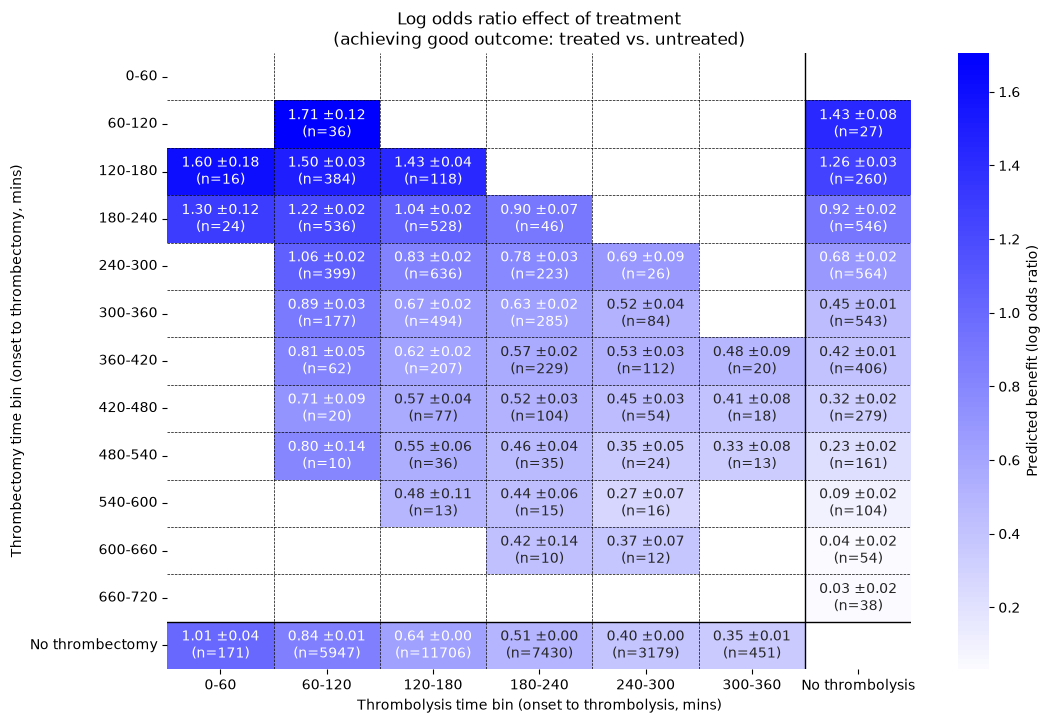

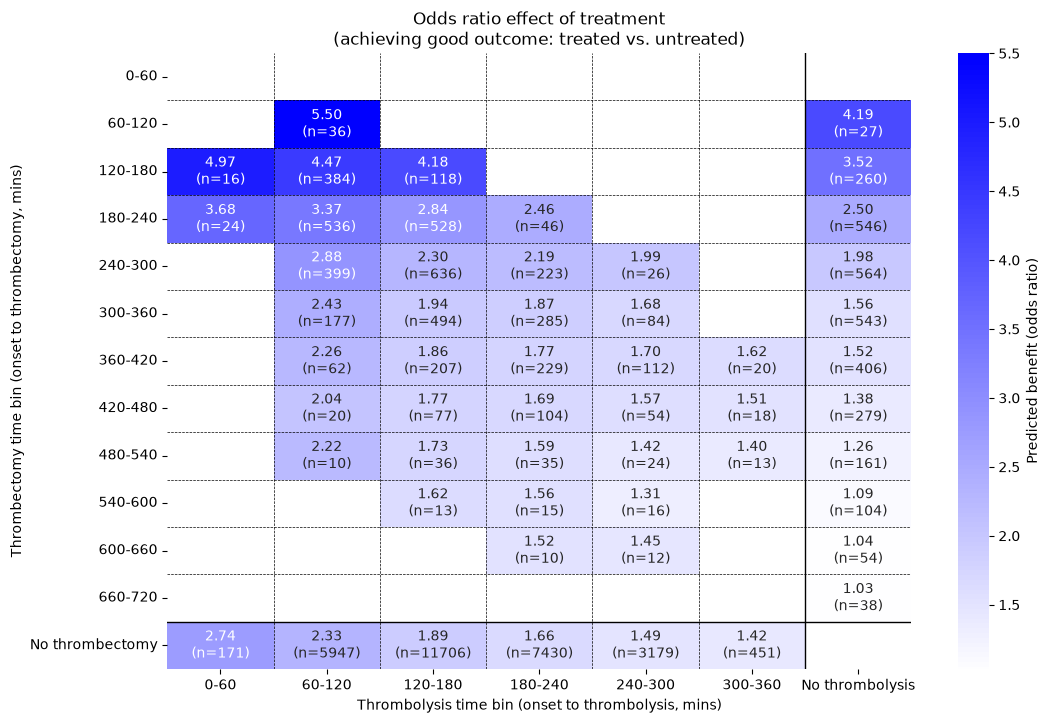

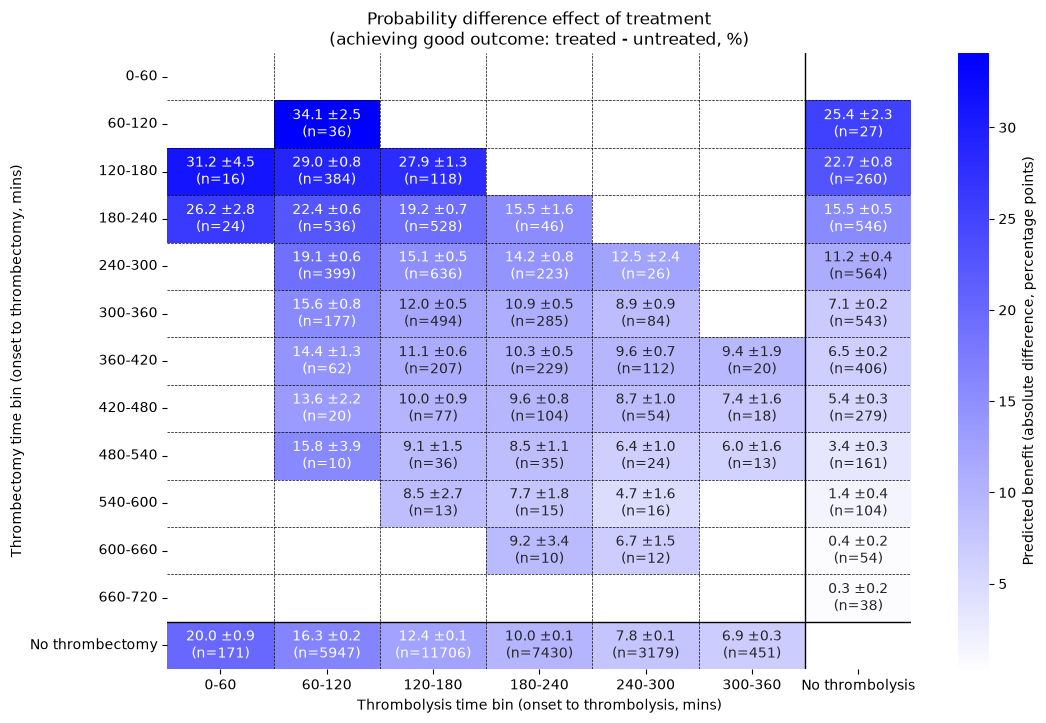

In [15]:
plot_time_heatmap(
    cf_times, "log_odds_diff_treated_no_treatment",
    title="Log odds ratio effect of treatment\n(achieving good outcome: treated vs. untreated)",
    cbar_label="Predicted benefit (log odds ratio)",
    filename="heatmap_log_odds", show_ci=True,
)

plot_time_heatmap(
    cf_times, "log_odds_diff_treated_no_treatment",
    title="Odds ratio effect of treatment\n(achieving good outcome: treated vs. untreated)",
    cbar_label="Predicted benefit (odds ratio)",
    filename="heatmap_odds", exponentiate=True, center=1,
)

plot_time_heatmap(
    cf_times, "treatment_diff_prob",
    title="Probability difference effect of treatment\n(achieving good outcome: treated - untreated, %)",
    cbar_label="Predicted benefit (absolute difference, percentage points)",
    filename="heatmap_diff_prob", scale=100, decimals=1, show_ci=True,
)

## Benefit by both treatment times (patients receiving both treatments)

An ordinary least squares (OLS) regression of individual predicted benefit (log odds ratio) on onset-to-thrombolysis and onset-to-thrombectomy time. This summarises how the fitted XGBoost model's estimated benefit changes with each time, holding the other constant.

Note: the 'observations' are model predictions, not independent outcomes, so OLS standard errors and p-values are too small. Treat the coefficients as a description of the S-learner, not as independent tests.

In [16]:
both = cf_times[cf_times["treatment_group"] == "both"].copy()

ols_both_times = sm.OLS(
    both["log_odds_diff_treated_no_treatment"],
    sm.add_constant(both[[TIME_THROMBOLYSIS, TIME_THROMBECTOMY]]),
).fit()
print(ols_both_times.summary())

params = ols_both_times.params


def linear_benefit(ivt_time, evt_time):
    """Predicted log odds benefit from the two-time regression."""
    return params["const"] + params[TIME_THROMBOLYSIS] * ivt_time + params[TIME_THROMBECTOMY] * evt_time

                                    OLS Regression Results                                    
Dep. Variable:     log_odds_diff_treated_no_treatment   R-squared:                       0.575
Model:                                            OLS   Adj. R-squared:                  0.575
Method:                                 Least Squares   F-statistic:                     3496.
Date:                                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                                        22:00:59   Log-Likelihood:                -207.28
No. Observations:                                5164   AIC:                             420.6
Df Residuals:                                    5161   BIC:                             440.2
Df Model:                                           2                                         
Covariance Type:                            nonrobust                                         
                                 coef    std err  

### Contour plot

Predicted benefit across both times from the regression above. The grey area (thrombolysis after thrombectomy) is outside the data.

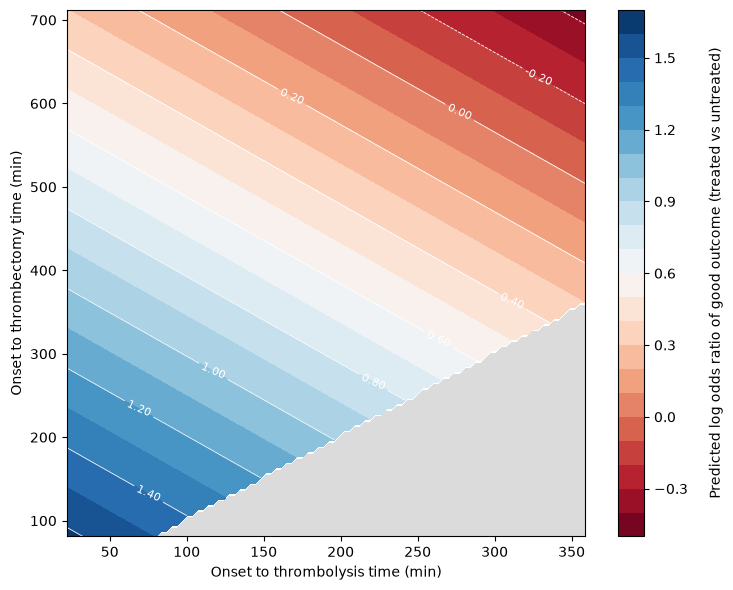

In [17]:
ivt_grid = np.linspace(both[TIME_THROMBOLYSIS].min(), both[TIME_THROMBOLYSIS].max(), 100)
evt_grid = np.linspace(both[TIME_THROMBECTOMY].min(), both[TIME_THROMBECTOMY].max(), 100)
ivt_mesh, evt_mesh = np.meshgrid(ivt_grid, evt_grid)

invalid = ivt_mesh > evt_mesh
benefit = np.ma.masked_where(invalid, linear_benefit(ivt_mesh, evt_mesh))

fig, ax = plt.subplots(figsize=(7.5, 6))
filled = ax.contourf(ivt_mesh, evt_mesh, benefit, levels=20, cmap="RdBu")
lines = ax.contour(ivt_mesh, evt_mesh, benefit, levels=10, colors="white", linewidths=0.6)
ax.clabel(lines, inline=True, fontsize=8, fmt="%.2f")
ax.contourf(ivt_mesh, evt_mesh, invalid, levels=[0.5, 1.5], colors="lightgrey", alpha=0.8)

fig.colorbar(filled, ax=ax).set_label(
    "Predicted log odds ratio of good outcome (treated vs untreated)", labelpad=15
)
ax.set_xlabel("Onset to thrombolysis time (min)")
ax.set_ylabel("Onset to thrombectomy time (min)")
fig.tight_layout()
fig.savefig(output_path("contour_plot.png"), dpi=300)
plt.show()

### Marginal effect plots

Left: benefit against thrombectomy time at fixed thrombolysis times. Right: benefit against thrombolysis time at fixed thrombectomy times. Lines are drawn only where thrombolysis is not after thrombectomy.

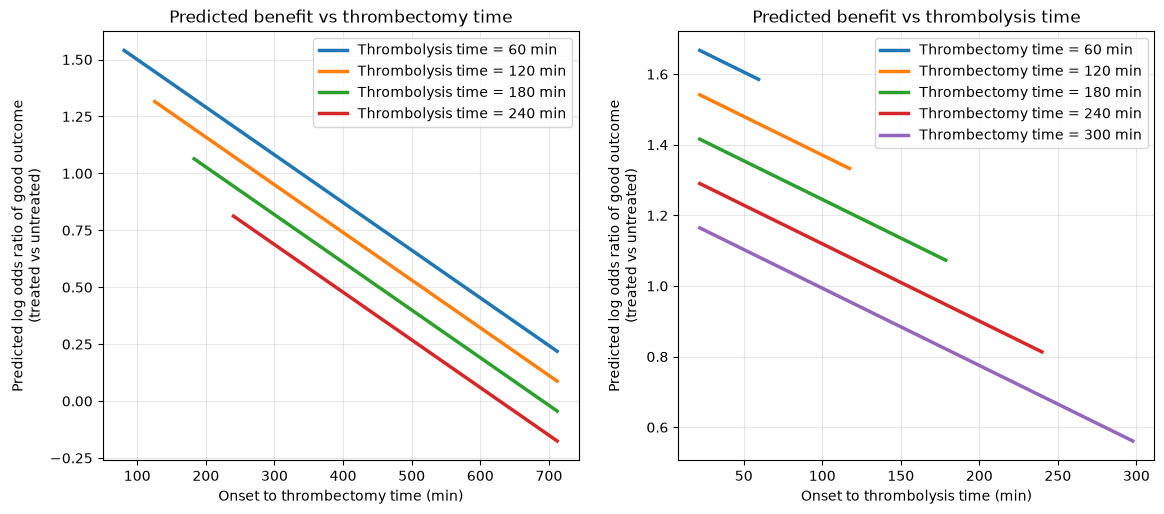

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
y_label = "Predicted log odds ratio of good outcome\n(treated vs untreated)"

evt_range = np.linspace(both[TIME_THROMBECTOMY].min(), both[TIME_THROMBECTOMY].max(), 100)
for ivt_time in [60, 120, 180, 240]:
    valid = evt_range >= ivt_time
    axes[0].plot(evt_range[valid], linear_benefit(ivt_time, evt_range[valid]),
                 linewidth=2.5, label=f"Thrombolysis time = {ivt_time} min")
axes[0].set_title("Predicted benefit vs thrombectomy time")
axes[0].set_xlabel("Onset to thrombectomy time (min)")

ivt_range = np.linspace(both[TIME_THROMBOLYSIS].min(), both[TIME_THROMBOLYSIS].max(), 100)
for evt_time in [60, 120, 180, 240, 300]:
    valid = ivt_range <= evt_time
    axes[1].plot(ivt_range[valid], linear_benefit(ivt_range[valid], evt_time),
                 linewidth=2.5, label=f"Thrombectomy time = {evt_time} min")
axes[1].set_title("Predicted benefit vs thrombolysis time")
axes[1].set_xlabel("Onset to thrombolysis time (min)")

for ax in axes:
    ax.set_ylabel(y_label)
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout(pad=2.0)
fig.savefig(output_path("marginal_effect_plot.png"), dpi=300)
plt.show()

## Benefit by time to treatment, for each treatment received

For each group, a simple linear regression of individual predicted benefit (log odds ratio) on onset-to-treatment time gives:

* **Benefit at time zero** (the intercept), with 95% CI.
* **Time at which predicted benefit reaches zero**: x = -intercept / slope. Its 95% CI uses the delta method:
  Var(x) = Var(a)/b^2 + a^2 Var(b)/b^4 - 2a Cov(a, b)/b^3, where a is the intercept and b the slope.
  This is an extrapolation when the zero point lies beyond the observed times.

The same caveat on standard errors applies as above (predictions are not independent observations).

**SHAP plots** explain the outcome model (`models_times[0]`, probability of good outcome), not the treatment effect. They show which features drive predicted outcome for each group. About 20% of the patients shown were in that model's training data (they were test patients for other folds).

In [19]:
def analyse_time_to_treatment(df, time_col, treatment_label, subtitle, filename=None):
    """Regress predicted benefit on time to treatment; print key results and plot."""
    benefit_col = "log_odds_diff_treated_no_treatment"
    ols = sm.OLS(df[benefit_col], sm.add_constant(df[[time_col]])).fit()
    print(ols.summary())

    intercept, slope = ols.params["const"], ols.params[time_col]
    ci = ols.conf_int().loc["const"]
    print(f"\nPredicted benefit at time zero (intercept): {intercept:.4f}, "
          f"95% CI: [{ci.iloc[0]:.4f}, {ci.iloc[1]:.4f}]")

    if np.isclose(slope, 0):
        print("Slope is approximately zero, so the time of zero benefit cannot be estimated reliably.")
    else:
        cov = ols.cov_params()
        x_at_zero = -intercept / slope
        variance = (
            cov.loc["const", "const"] / slope**2
            + intercept**2 * cov.loc[time_col, time_col] / slope**4
            - 2 * intercept * cov.loc["const", time_col] / slope**3
        )
        half_width = 1.96 * np.sqrt(max(variance, 0))
        print(f"Time at which predicted benefit is zero: {x_at_zero:.0f} mins, "
              f"95% CI: [{x_at_zero - half_width:.0f}, {x_at_zero + half_width:.0f}] mins")

    fig, ax = plt.subplots(figsize=(7, 6))
    sns.regplot(x=time_col, y=benefit_col, data=df, ci=95, ax=ax,
                scatter_kws={"s": 10, "alpha": 0.5}, line_kws={"color": "red"})
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_title(f"Effect of {treatment_label} time on predicted benefit (good outcome)\n({subtitle})")
    ax.set_xlabel(f"Onset to {treatment_label} time (mins)")
    ax.set_ylabel("Predicted benefit\n(log odds ratio of good outcome vs no treatment)")
    if filename:
        fig.savefig(output_path(f"{filename}.png"), dpi=300, bbox_inches="tight")
    plt.show()
    return ols


def plot_outcome_shap(df, title):
    """SHAP beeswarm for the Part A outcome model (fold 1) on the given patients."""
    shap_values = shap.Explainer(models_times[0])(df[X_FIELDS_TIMES])
    shap.plots.beeswarm(shap_values, max_display=99, show=False)
    plt.title(title)
    plt.show()

### Thrombectomy alone

                                    OLS Regression Results                                    
Dep. Variable:     log_odds_diff_treated_no_treatment   R-squared:                       0.684
Model:                                            OLS   Adj. R-squared:                  0.684
Method:                                 Least Squares   F-statistic:                     6445.
Date:                                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                                        22:01:00   Log-Likelihood:                 412.39
No. Observations:                                2983   AIC:                            -820.8
Df Residuals:                                    2981   BIC:                            -808.8
Df Model:                                           1                                         
Covariance Type:                            nonrobust                                         
                                 coef    std err  

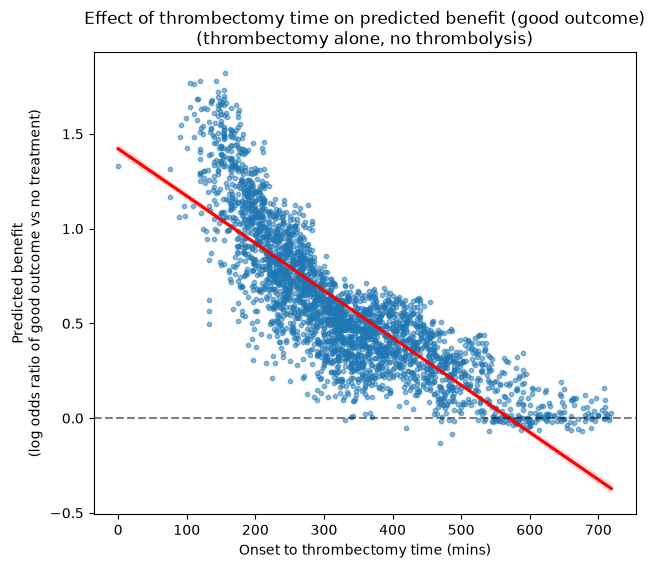

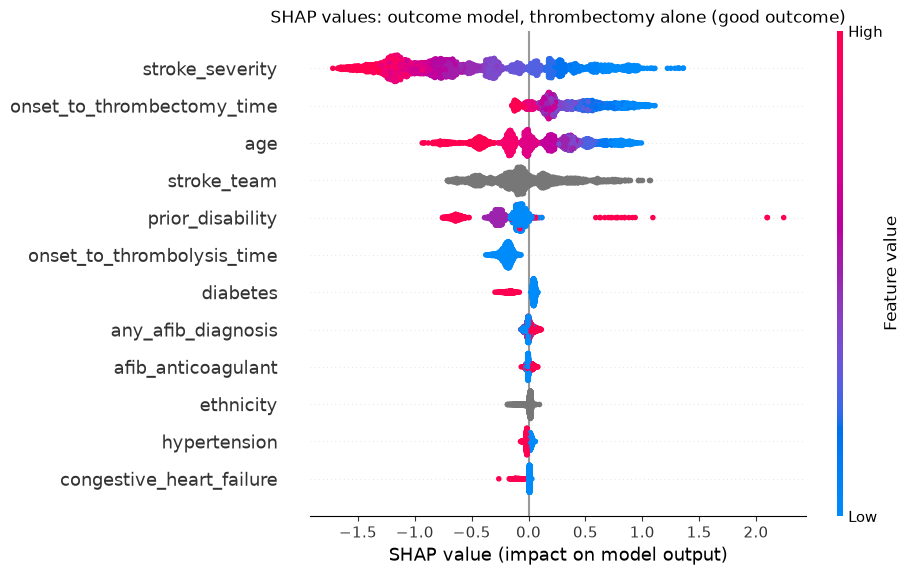

In [20]:
only_thrombectomy = cf_times[cf_times["treatment_group"] == "thrombectomy_only"].copy()
analyse_time_to_treatment(only_thrombectomy, TIME_THROMBECTOMY, "thrombectomy",
                          "thrombectomy alone, no thrombolysis", "time_effect_thrombectomy_alone")
plot_outcome_shap(only_thrombectomy, "SHAP values: outcome model, thrombectomy alone (good outcome)")

### Thrombolysis alone

                                    OLS Regression Results                                    
Dep. Variable:     log_odds_diff_treated_no_treatment   R-squared:                       0.364
Model:                                            OLS   Adj. R-squared:                  0.364
Method:                                 Least Squares   F-statistic:                 1.656e+04
Date:                                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                                        22:01:02   Log-Likelihood:                 6281.9
No. Observations:                               28884   AIC:                        -1.256e+04
Df Residuals:                                   28882   BIC:                        -1.254e+04
Df Model:                                           1                                         
Covariance Type:                            nonrobust                                         
                                 coef    std err  

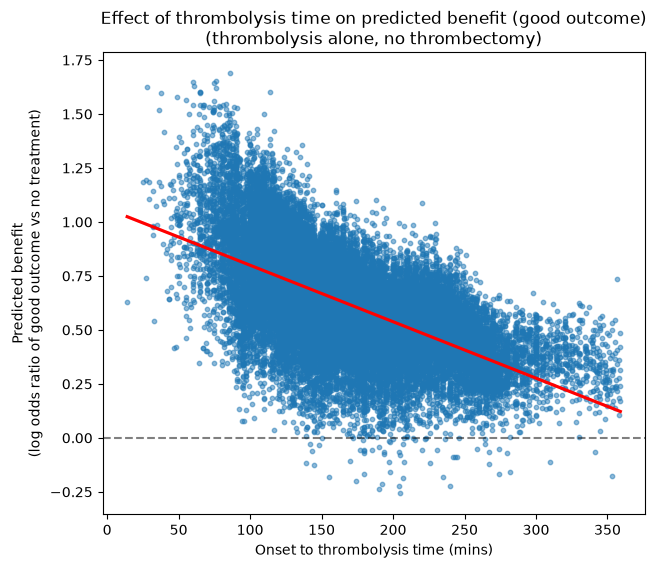

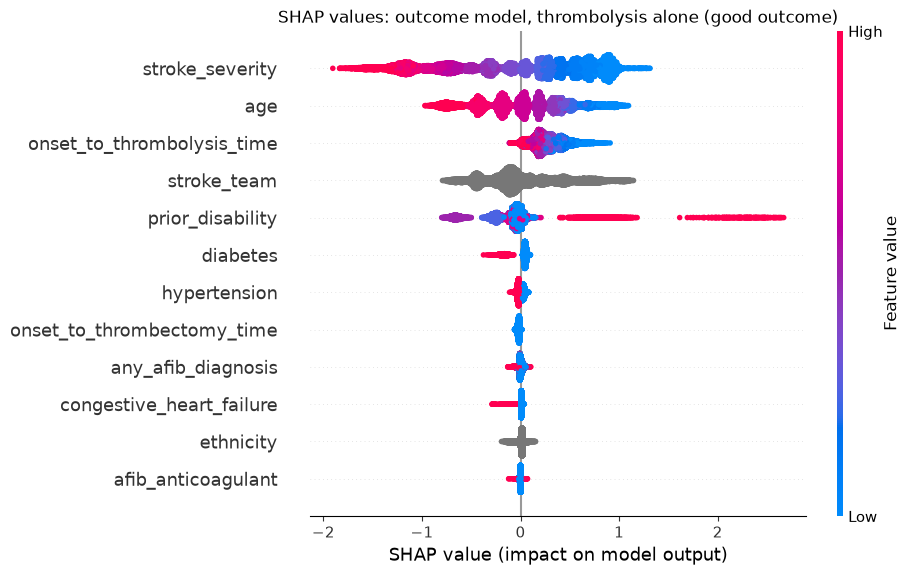

In [21]:
only_thrombolysis = cf_times[cf_times["treatment_group"] == "thrombolysis_only"].copy()
analyse_time_to_treatment(only_thrombolysis, TIME_THROMBOLYSIS, "thrombolysis",
                          "thrombolysis alone, no thrombectomy", "time_effect_thrombolysis_alone")
plot_outcome_shap(only_thrombolysis, "SHAP values: outcome model, thrombolysis alone (good outcome)")

### Thrombolysis and thrombectomy: time to thrombectomy, then time to thrombolysis

Each time is analysed on its own here. The two times are correlated (thrombectomy follows thrombolysis), so these single-time slopes partly reflect the other time; the two-time regression above separates them. The SHAP plot is shown once, since both analyses use the same patients.

                                    OLS Regression Results                                    
Dep. Variable:     log_odds_diff_treated_no_treatment   R-squared:                       0.513
Model:                                            OLS   Adj. R-squared:                  0.513
Method:                                 Least Squares   F-statistic:                     5446.
Date:                                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                                        22:01:09   Log-Likelihood:                -558.58
No. Observations:                                5164   AIC:                             1121.
Df Residuals:                                    5162   BIC:                             1134.
Df Model:                                           1                                         
Covariance Type:                            nonrobust                                         
                                 coef    std err  

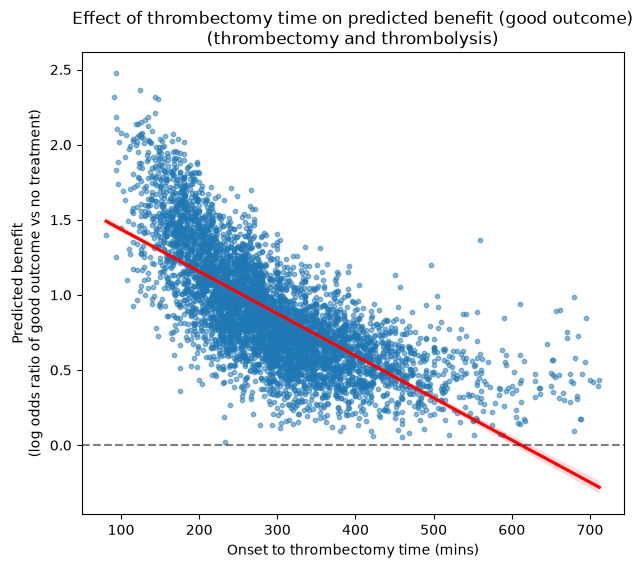

                                    OLS Regression Results                                    
Dep. Variable:     log_odds_diff_treated_no_treatment   R-squared:                       0.389
Model:                                            OLS   Adj. R-squared:                  0.389
Method:                                 Least Squares   F-statistic:                     3284.
Date:                                Tue, 17 Nov 2026   Prob (F-statistic):               0.00
Time:                                        22:01:10   Log-Likelihood:                -1147.3
No. Observations:                                5164   AIC:                             2299.
Df Residuals:                                    5162   BIC:                             2312.
Df Model:                                           1                                         
Covariance Type:                            nonrobust                                         
                                 coef    std err  

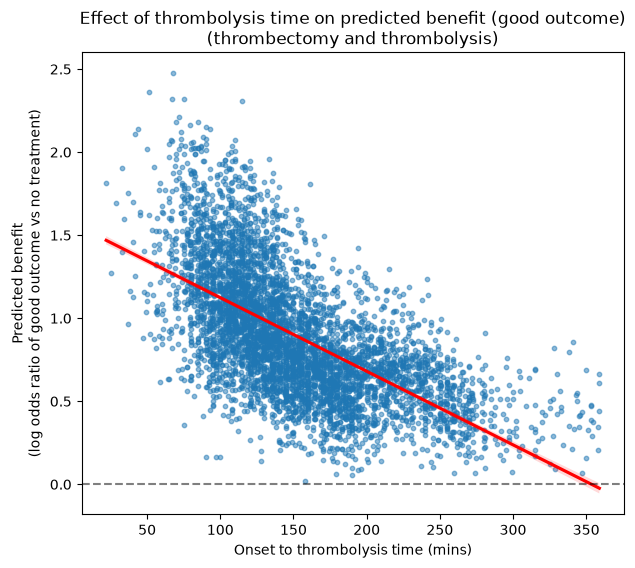

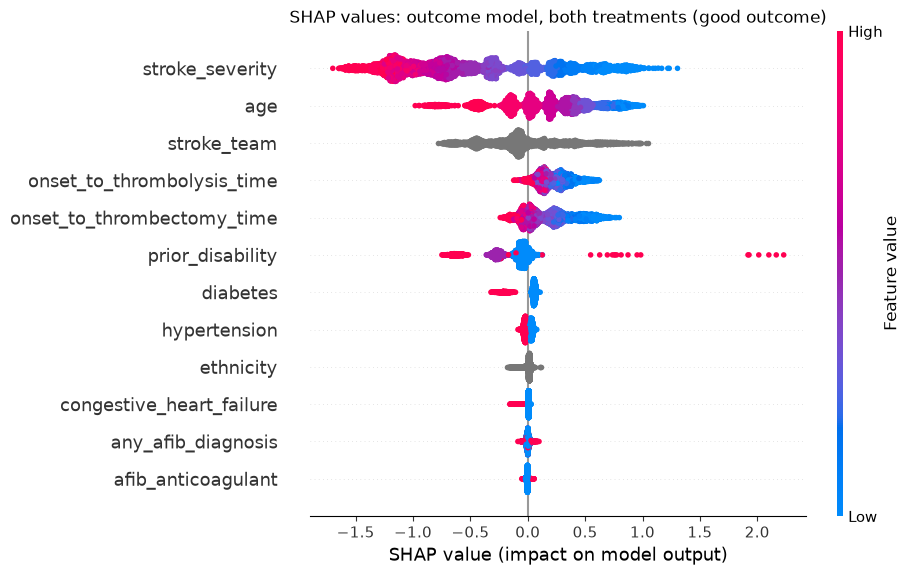

In [22]:
analyse_time_to_treatment(both, TIME_THROMBECTOMY, "thrombectomy",
                          "thrombectomy and thrombolysis", "time_effect_thrombectomy_both")
analyse_time_to_treatment(both, TIME_THROMBOLYSIS, "thrombolysis",
                          "thrombectomy and thrombolysis", "time_effect_thrombolysis_both")
plot_outcome_shap(both, "SHAP values: outcome model, both treatments (good outcome)")

# Part B: S-learner with grouped treatment arms

## Method

The two continuous treatment times are replaced by one categorical feature, `treatment_group` (eight levels: neither, plus seven modality x early/late arms). Otherwise the approach matches Part A: the same outcome, the same adjustment features, 5-fold stratified cross-validation, and an XGBoost classifier. Hyperparameters are tuned separately for this model, in the same way as Part A (log loss, no class weighting).

**Counterfactual**: for every patient in each held-out fold, predict with the actual arm, then with the arm set to 'neither'. The difference is the individual estimated treatment effect (probability and log-odds scales). Averaging within an arm gives the arm's conditional average treatment effect (CATE) for patients who actually received that arm.

Compared with Part A, grouping removes within-arm time detail but allows the model to treat each arm as a separate level, and produces simple per-arm summaries.

In [23]:
best_params_arms, tuning_arms = tune_xgb(data[X_FIELDS_GROUPS], y)
print("Selected hyperparameters:", best_params_arms)
display(tuning_arms.head(10))

folds_arms = split_folds(data[X_FIELDS_GROUPS], y)
models_arms, performance_arms = train_and_evaluate(folds_arms, xgb_factory(**best_params_arms))
performance_arms

Optuna: 47 trials completed, 13 pruned
Selected hyperparameters: {'max_depth': 3, 'learning_rate': 0.02822826941042137, 'n_estimators': 1000, 'min_child_weight': 2.4784388747125567, 'subsample': 0.8473807005175394, 'colsample_bytree': 0.520498081869668, 'reg_lambda': 2.280198529662911, 'reg_alpha': 2.700155333077662, 'gamma': 0.011269741369956765}


,max_depth,learning_rate,n_estimators,min_child_weight,subsample,colsample_bytree,reg_lambda,reg_alpha,gamma,log loss,AUC
trial,,,,,,,,,,,
45,3.0,0.0282,1000.0,2.4784,0.8474,0.5205,2.2802,2.7002,0.0113,0.5695,0.7637
33,3.0,0.0228,950.0,2.5269,0.8484,0.5131,2.1372,0.6157,0.0011,0.5696,0.7637
54,3.0,0.0201,950.0,1.8306,0.8984,0.5069,0.6609,0.4033,0.0023,0.5696,0.7636
34,3.0,0.0213,950.0,3.4001,0.8181,0.5321,1.3052,2.9828,0.0150,0.5697,0.7635
37,3.0,0.0260,850.0,4.3382,0.7852,0.5183,1.1815,1.5273,0.0018,0.5697,0.7636
44,3.0,0.0272,1000.0,1.8713,0.8381,0.5263,5.0288,0.9716,0.0025,0.5697,0.7636
49,3.0,0.0228,900.0,2.1398,0.8208,0.5010,1.4225,0.1879,0.0095,0.5697,0.7636
39,3.0,0.0225,850.0,1.0638,0.8264,0.5037,1.8255,0.1309,0.0014,0.5697,0.7635
50,3.0,0.0221,1000.0,4.3977,0.8760,0.5019,6.1279,0.4206,0.0015,0.5697,0.7635


,AUC,balanced_accuracy,actual_positive_rate,predicted_positive_rate,mean_predicted_probability
split,,,,,
1,0.7668,0.6884,0.4222,0.3814,0.4246
2,0.7622,0.6847,0.4222,0.3747,0.4193
3,0.7659,0.6871,0.4222,0.3836,0.4231
4,0.7651,0.6866,0.4222,0.3758,0.4203
5,0.7619,0.6884,0.4222,0.3871,0.4240


In [24]:
def predict_arm_counterfactuals(models, folds):
    """Out-of-fold predictions with the actual treatment arm and with the arm set to 'neither'."""
    frames = []
    for model, (_, test_X, _, _) in zip(models, folds):
        untreated_X = test_X.assign(treatment_group=pd.Categorical(
            ["neither"] * len(test_X), categories=test_X["treatment_group"].cat.categories
        ))
        fold_cf = test_X.copy()
        fold_cf["y_prob_treated"] = model.predict_proba(test_X)[:, 1]
        fold_cf["y_prob_untreated"] = model.predict_proba(untreated_X)[:, 1]
        frames.append(fold_cf)

    cf = pd.concat(frames, ignore_index=True)
    cf["prob_shift"] = cf["y_prob_treated"] - cf["y_prob_untreated"]
    cf["log_odds_shift"] = to_log_odds(cf["y_prob_treated"]) - to_log_odds(cf["y_prob_untreated"])
    return cf


cf_arms = predict_arm_counterfactuals(models_arms, folds_arms)

## CATE by treatment arm

Mean individual effect with 95% CI (mean +/- 1.96 x SD / sqrt(n)), on the probability scale and the log-odds scale. As in Part A, the CI reflects variation between patients' predicted effects, not model uncertainty.

In [25]:
ARM_ORDER = [group for group in TREATMENT_GROUP_ORDER if group != "neither"]
ARM_LABELS = {
    "early_thrombolysis_only": "Early thrombolysis only",
    "late_thrombolysis_only": "Late thrombolysis only",
    "early_thrombectomy_only": "Early thrombectomy only",
    "late_thrombectomy_only": "Late thrombectomy only",
    "early_both": "Early both",
    "early_thrombolysis_late_thrombectomy": "Early thrombolysis,\nlate thrombectomy",
    "late_both": "Late both",
}


def summarise_by_arm(cf, value_col):
    """Mean, SD, n and 95% CI of value_col for each treatment arm."""
    summary = cf.groupby("treatment_group", observed=True)[value_col].agg(["mean", "std", "count"])
    half_width = 1.96 * summary["std"] / np.sqrt(summary["count"])
    summary["95% CI lower"] = summary["mean"] - half_width
    summary["95% CI upper"] = summary["mean"] + half_width
    return summary.reindex(ARM_ORDER)


def plot_arm_estimates(summary, xlabel, filename):
    """Forest plot of per-arm estimates with 95% CIs."""
    labels = [f"{ARM_LABELS[arm]}\n(n={n:.0f})" for arm, n in summary["count"].items()]
    y_pos = np.arange(len(summary))[::-1]

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.errorbar(
        summary["mean"], y_pos,
        xerr=[summary["mean"] - summary["95% CI lower"], summary["95% CI upper"] - summary["mean"]],
        fmt="o", markersize=7, capsize=5,
    )
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels)
    ax.axvline(0, linestyle="--", alpha=0.7)
    ax.grid(axis="x", linestyle="--", alpha=0.7)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"Treatment arm (early: thrombolysis <= {CUTOFF} min, thrombectomy < {CUTOFF} min)",
                  labelpad=15)
    fig.tight_layout(pad=2)
    fig.savefig(output_path(f"{filename}.png"), dpi=300)
    plt.show()


arm_summary_prob = summarise_by_arm(cf_arms, "prob_shift")
arm_summary_log_odds = summarise_by_arm(cf_arms, "log_odds_shift")
arm_summary_prob.round(4)

,mean,std,count,95% CI lower,95% CI upper
treatment_group,,,,,
early_thrombolysis_only,0.1249,0.0480,27695,0.1243,0.1255
late_thrombolysis_only,0.0813,0.0320,1189,0.0795,0.0832
early_thrombectomy_only,0.1725,0.0654,1107,0.1686,0.1763
late_thrombectomy_only,0.0776,0.0343,1876,0.0760,0.0791
early_both,0.2169,0.0728,2309,0.2139,0.2199
early_thrombolysis_late_thrombectomy,0.1055,0.0397,2714,0.1040,0.1070
late_both,0.1294,0.0514,141,0.1209,0.1379


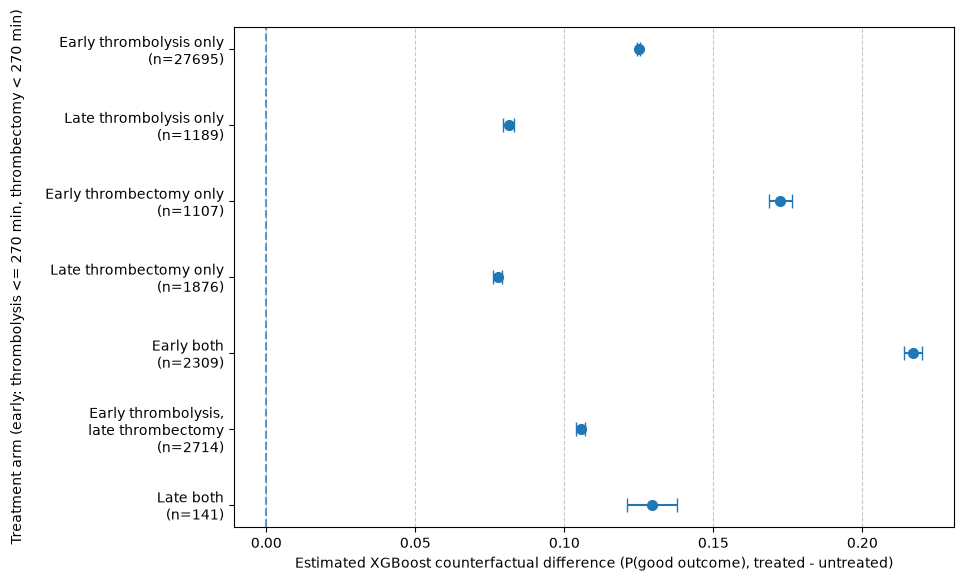

In [26]:
plot_arm_estimates(
    arm_summary_prob,
    "Estimated XGBoost counterfactual difference (P(good outcome), treated - untreated)",
    "counterfactual_cate_probabilities_estimates",
)

In [27]:
arm_summary_log_odds.round(4)

,mean,std,count,95% CI lower,95% CI upper
treatment_group,,,,,
early_thrombolysis_only,0.6415,0.1834,27695,0.6394,0.6437
late_thrombolysis_only,0.4120,0.1171,1189,0.4053,0.4186
early_thrombectomy_only,0.9982,0.2317,1107,0.9845,1.0118
late_thrombectomy_only,0.4723,0.1713,1876,0.4645,0.4800
early_both,1.1566,0.2335,2309,1.1471,1.1662
early_thrombolysis_late_thrombectomy,0.6047,0.1642,2714,0.5985,0.6109
late_both,0.6851,0.2213,141,0.6486,0.7216


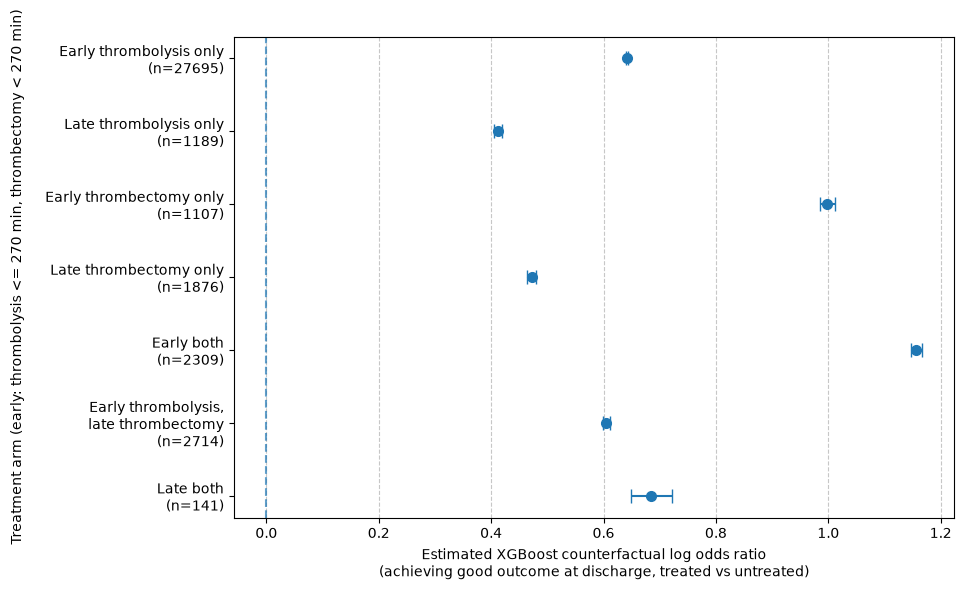

In [28]:
plot_arm_estimates(
    arm_summary_log_odds,
    "Estimated XGBoost counterfactual log odds ratio\n(achieving good outcome at discharge, treated vs untreated)",
    "counterfactual_cate_log_odds_estimates",
)

# Part C: Meta-model of benefit

## Method

An XGBoost regression model is fitted to the individual estimated benefit (Part B log odds shift) of all treated patients, using the same features as the Part B model (including treatment arm). SHAP values for this meta-model show which characteristics are associated with larger or smaller estimated benefit (treatment effect heterogeneity).

* In-sample R-squared shows how much of the S-learner's benefit variation the meta-model reproduces. It is optimistic because the model is evaluated on its own training data, so a 5-fold out-of-fold R-squared is also reported.
* The meta-model describes the S-learner's estimates. It cannot find heterogeneity the S-learner did not estimate, and inherits any bias in it.

In [29]:
benefit_df = cf_arms[cf_arms["treatment_group"] != "neither"].copy()
meta_X = benefit_df[X_FIELDS_GROUPS]
meta_y = benefit_df["log_odds_shift"]


def make_meta_model():
    return XGBRegressor(enable_categorical=True, verbosity=0, random_state=RANDOM_STATE, eval_metric="rmse")


meta_model = make_meta_model().fit(meta_X, meta_y)
benefit_df["predicted_log_odds_shift"] = meta_model.predict(meta_X)
benefit_df["oof_predicted_log_odds_shift"] = cross_val_predict(
    make_meta_model(), meta_X, meta_y,
    cv=KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE),
)

r2_in_sample = r2_score(meta_y, benefit_df["predicted_log_odds_shift"])
r2_out_of_fold = r2_score(meta_y, benefit_df["oof_predicted_log_odds_shift"])
print(f"Meta-model R-squared: in-sample {r2_in_sample:.4f}, out-of-fold {r2_out_of_fold:.4f}")

Meta-model R-squared: in-sample 0.9669, out-of-fold 0.9319


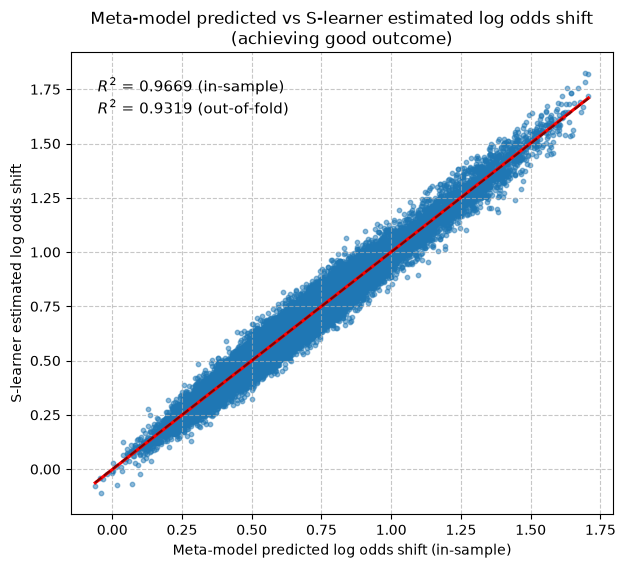

In [30]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.regplot(x="predicted_log_odds_shift", y="log_odds_shift", data=benefit_df, ci=95, ax=ax,
            scatter_kws={"s": 10, "alpha": 0.5}, line_kws={"color": "red"})
limits = [benefit_df["predicted_log_odds_shift"].min(), benefit_df["predicted_log_odds_shift"].max()]
ax.plot(limits, limits, color="black", linestyle="--", alpha=0.5)  # y = x
ax.set_title("Meta-model predicted vs S-learner estimated log odds shift\n(achieving good outcome)")
ax.set_xlabel("Meta-model predicted log odds shift (in-sample)")
ax.set_ylabel("S-learner estimated log odds shift")
ax.grid(linestyle="--", alpha=0.7)
ax.text(0.05, 0.95, f"$R^2$ = {r2_in_sample:.4f} (in-sample)\n$R^2$ = {r2_out_of_fold:.4f} (out-of-fold)",
        transform=ax.transAxes, fontsize=11, verticalalignment="top")
plt.show()

## SHAP values for the meta-model

Positive SHAP values mean the feature value is associated with *greater* estimated benefit from treatment.

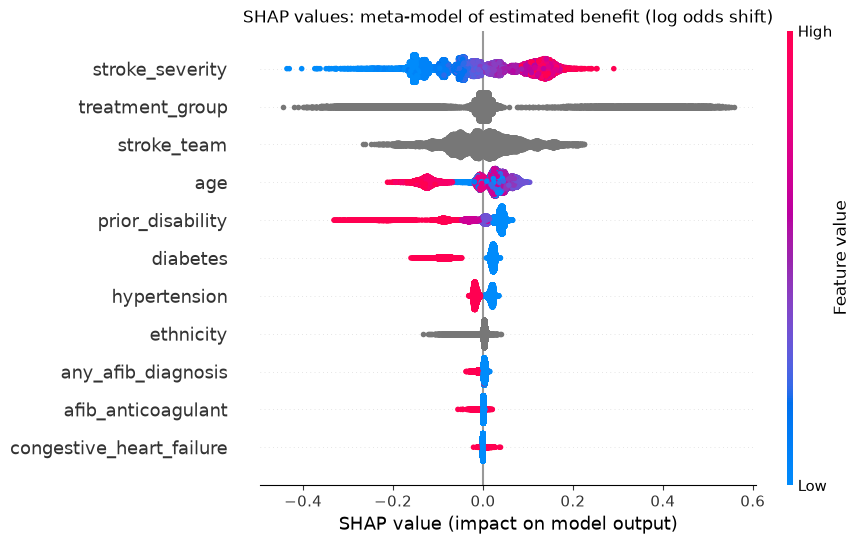

In [31]:
meta_shap_values = shap.Explainer(meta_model)(meta_X)
shap.plots.beeswarm(meta_shap_values, max_display=99, show=False)
plt.title("SHAP values: meta-model of estimated benefit (log odds shift)")
plt.savefig(output_path("treatment_effect_shap_beeswarm.png"), dpi=300, bbox_inches="tight")
plt.show()

### SHAP values by feature value

One panel per feature, ordered by mean |SHAP|, all on the same y-axis scale. Box whiskers show the full range. Stroke teams are sorted by mean SHAP value (labels hidden). For stroke severity, every fifth NIHSS value is labelled.

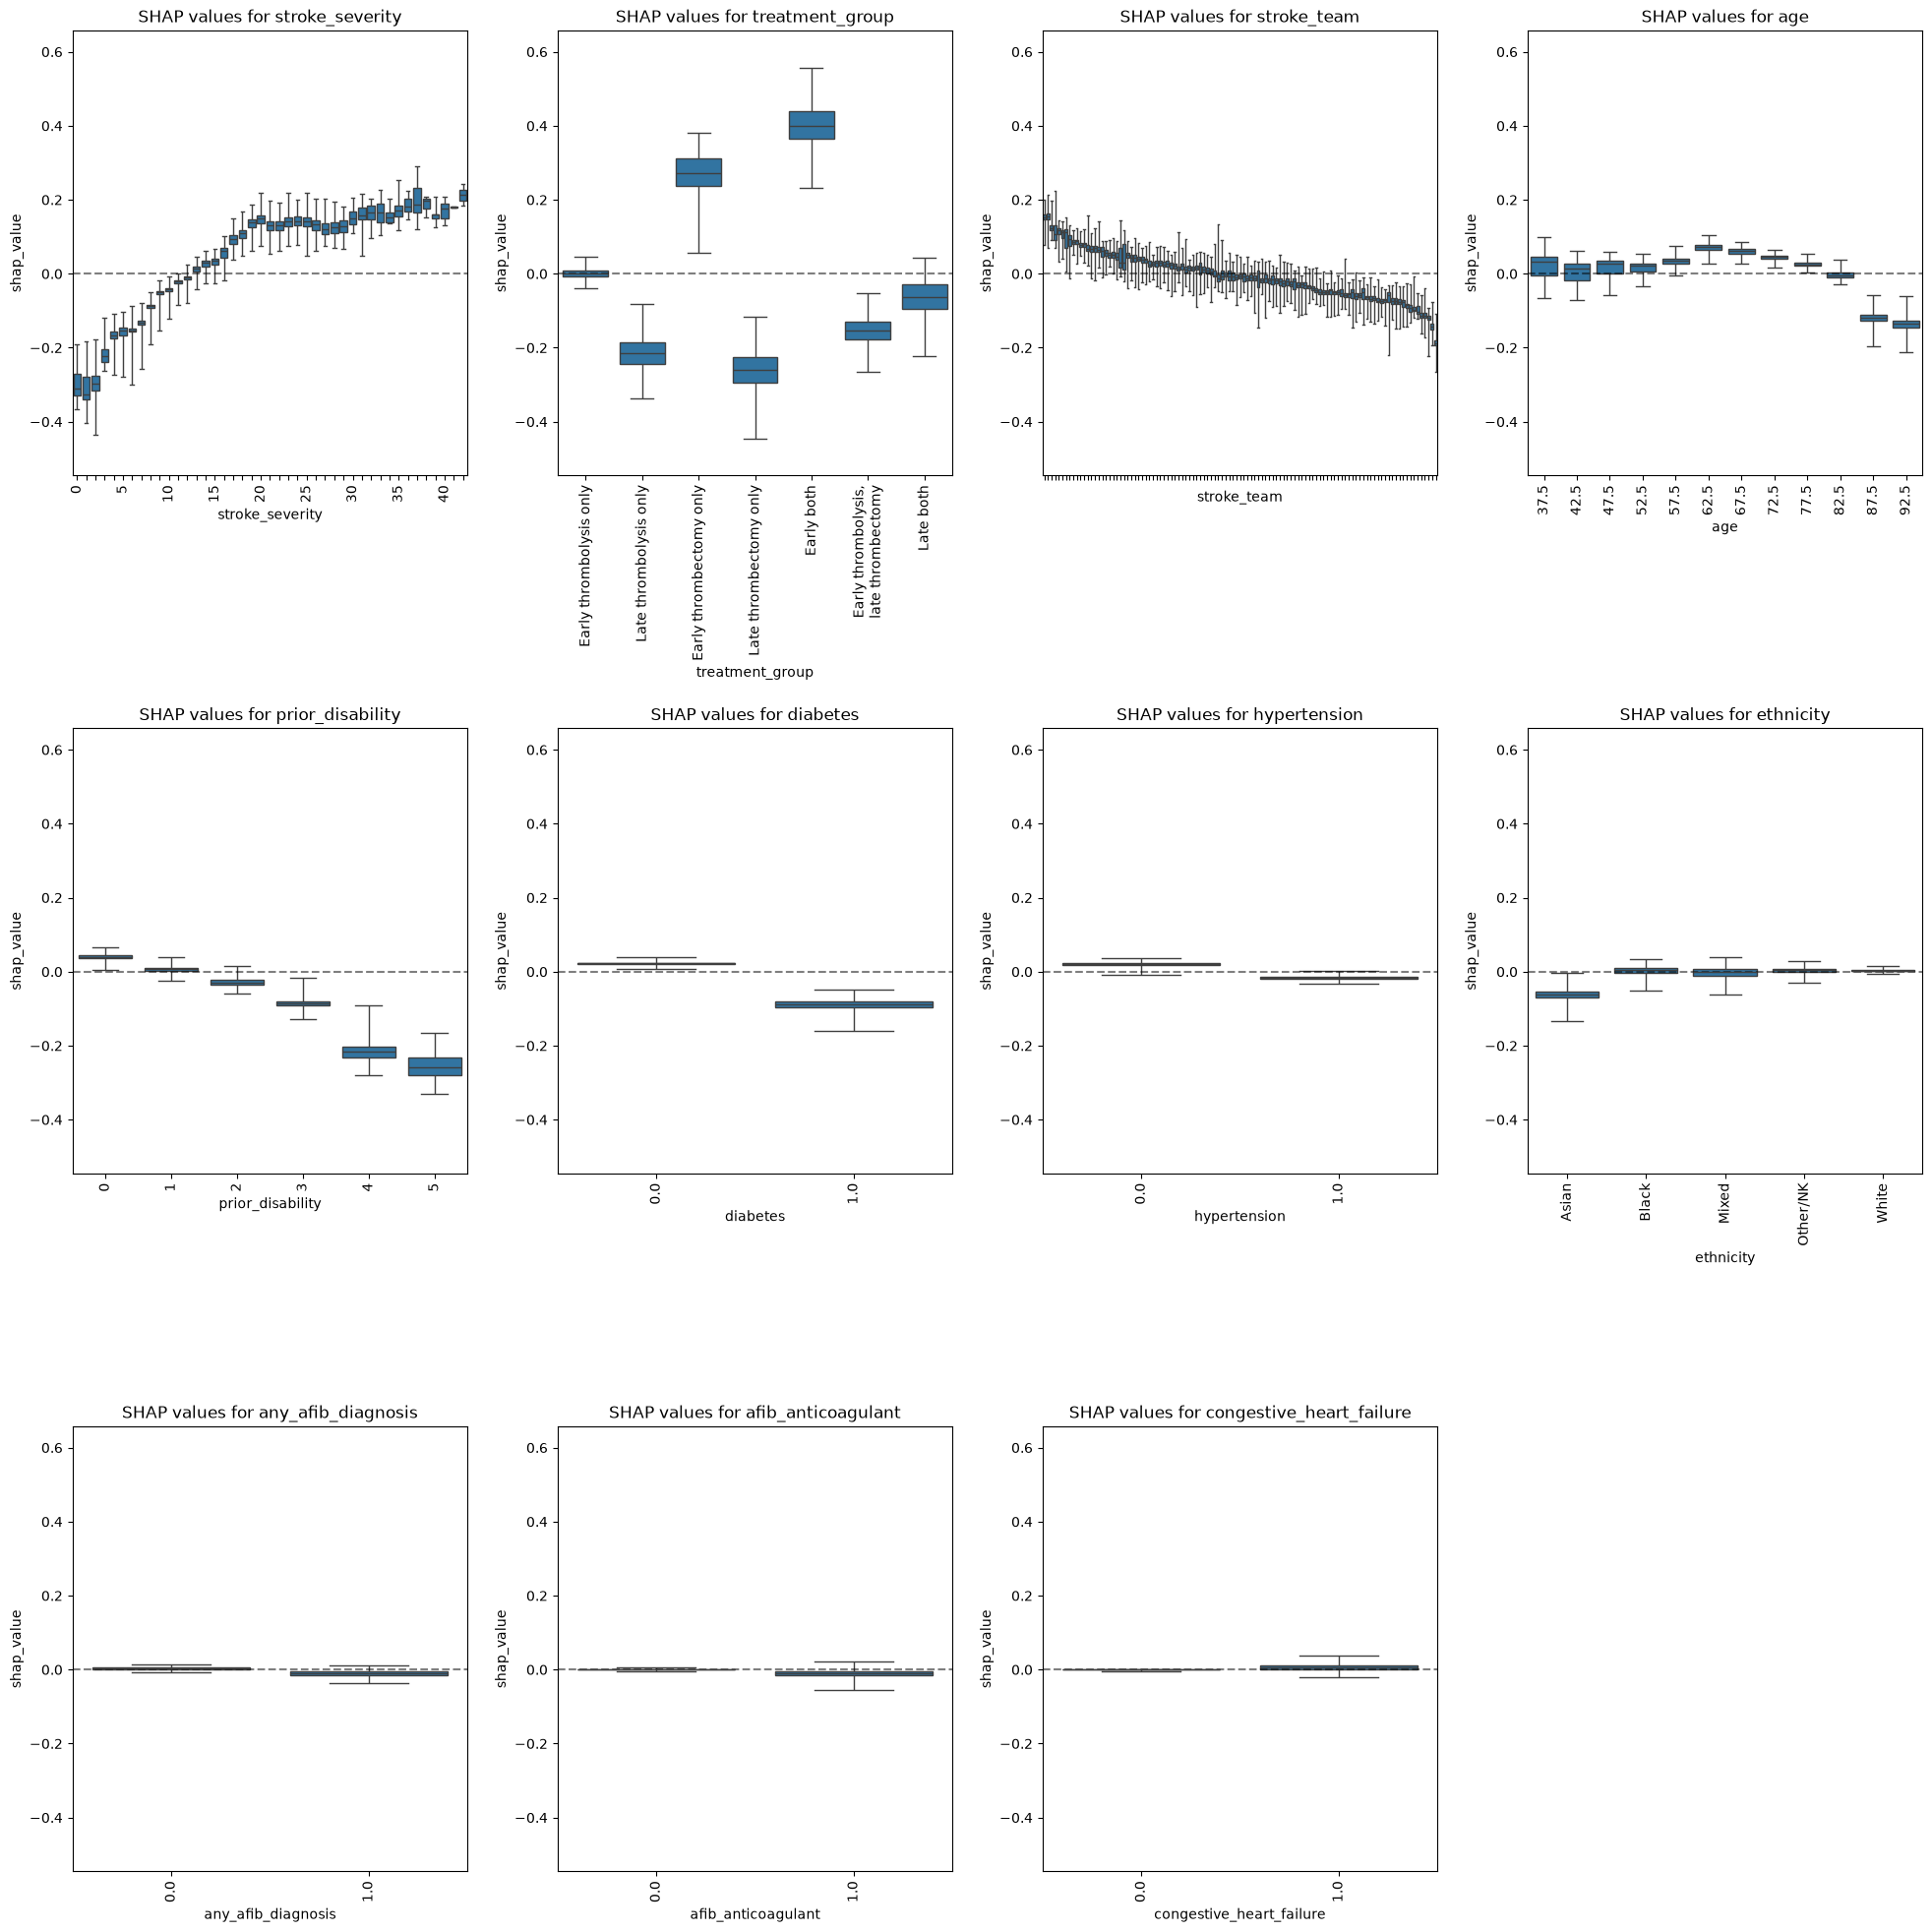

In [32]:
meta_shap_df = pd.DataFrame(meta_shap_values.values, columns=meta_X.columns)
features_by_importance = meta_shap_df.abs().mean().sort_values(ascending=False).index.tolist()

shap_range = meta_shap_df.min().min(), meta_shap_df.max().max()
padding = 0.1 * (shap_range[1] - shap_range[0])
y_limits = (shap_range[0] - padding, shap_range[1] + padding)

fig, axes = plt.subplots(3, 4, figsize=(20, 20))

for ax, feature in zip(axes.flat, features_by_importance):
    plot_df = pd.DataFrame({
        "feature_value": meta_X[feature].values,
        "shap_value": meta_shap_df[feature].values,
    })

    if feature == "stroke_team":
        team_order = plot_df.groupby("feature_value", observed=True)["shap_value"].mean()
        team_order = team_order.sort_values(ascending=False).index.tolist()
        plot_df["feature_value"] = pd.Categorical(plot_df["feature_value"].astype(str),
                                                  categories=[str(t) for t in team_order], ordered=True)
    elif feature == "treatment_group":
        plot_df["feature_value"] = pd.Categorical(
            plot_df["feature_value"].astype(str).map(ARM_LABELS),
            categories=[ARM_LABELS[arm] for arm in ARM_ORDER], ordered=True,
        )

    sns.boxplot(x="feature_value", y="shap_value", data=plot_df, ax=ax, whis=(0, 100))
    ax.set_title(f"SHAP values for {feature}")
    ax.set_xlabel(feature)
    ax.tick_params(axis="x", rotation=90)
    ax.axhline(0, color="black", linestyle="--", alpha=0.5)
    ax.set_ylim(y_limits)

    if feature == "stroke_team":
        ax.set_xticklabels([])
    elif feature == "stroke_severity":
        tick_values = [float(label.get_text()) for label in ax.get_xticklabels()]
        ax.set_xticklabels([f"{v:.0f}" if v % 5 == 0 else "" for v in tick_values])

# Hide unused panels
for ax in axes.flat[len(features_by_importance):]:
    ax.axis("off")

plt.tight_layout(pad=2)
plt.savefig(output_path("treatment_effect_shap_box_plots.png"), dpi=300, bbox_inches="tight")
plt.show()

# Part D: Sensitivity analysis

The S-learner estimates rest on assumptions and analytic choices. This section tests how far the main (Part B) per-arm estimates depend on them:

| Concern | Analysis |
|---|---|
| **Positivity / overlap**: are there comparable untreated patients for treated patients? | D1: propensity model for receiving any reperfusion treatment; check its distribution; re-estimate after trimming extreme propensities (in D2). |
| **Analytic choices**: class weighting, fold allocation, outcome definition, early/late cutoff, covariate set, population, model flexibility, model class | D2: re-run the Part B pipeline under alternative specifications and compare per-arm estimates with the base case. |
| **Unmeasured confounding** (e.g. confounding by indication: clinicians' judgement of likely benefit) | D3: E-values for each arm's odds ratio. |
| **Uncertainty not captured by current CIs**, and other designs | D4: further options (not run here). |

Runtime: D2 fits 5 models for each scenario (15 scenarios), so it takes several minutes.

## D1. Overlap (positivity)

An XGBoost classifier predicts the probability of receiving any reperfusion treatment (thrombolysis and/or thrombectomy) from the adjustment features, using out-of-fold predictions. If treated and untreated patients have very different propensity distributions, or many patients have propensities near 0 or 1, the S-learner has to extrapolate for those patients and its counterfactual predictions are less reliable.

A high propensity-model AUC is expected here (stroke team strongly predicts treatment), but values close to 1 would signal poor overlap. Patients outside `PROPENSITY_TRIM` are counted by arm and are excluded in the trimmed scenario in D2.

Propensity model AUC (out-of-fold): 0.751


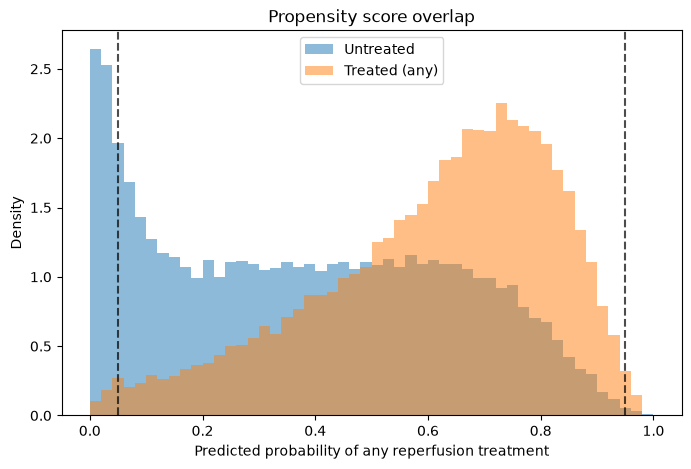

,n outside trim range,proportion outside trim range
treatment_group,,
neither,4669,0.124
early_thrombolysis_only,346,0.012
late_thrombolysis_only,13,0.011
early_thrombectomy_only,32,0.029
late_thrombectomy_only,45,0.024
early_both,41,0.018
early_thrombolysis_late_thrombectomy,31,0.011
late_both,1,0.007


In [33]:
PROPENSITY_TRIM = (0.05, 0.95)

any_treatment = (data["treatment_group"] != "neither").astype(int)
propensity_features = ADJUSTMENT_FEATURES + CATEGORICAL_FEATURES

data["propensity_any_treatment"] = cross_val_predict(
    XGBClassifier(enable_categorical=True, verbosity=0, random_state=RANDOM_STATE, eval_metric="logloss"),
    data[propensity_features], any_treatment,
    cv=StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE),
    method="predict_proba",
)[:, 1]

print(f"Propensity model AUC (out-of-fold): "
      f"{roc_auc_score(any_treatment, data['propensity_any_treatment']):.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
for label, mask in [("Untreated", any_treatment == 0), ("Treated (any)", any_treatment == 1)]:
    ax.hist(data.loc[mask, "propensity_any_treatment"], bins=50, range=(0, 1),
            density=True, alpha=0.5, label=label)
for limit in PROPENSITY_TRIM:
    ax.axvline(limit, color="black", linestyle="--", alpha=0.7)
ax.set_xlabel("Predicted probability of any reperfusion treatment")
ax.set_ylabel("Density")
ax.set_title("Propensity score overlap")
ax.legend()
fig.savefig(output_path("sensitivity_propensity_overlap.png"), dpi=300, bbox_inches="tight")
plt.show()

outside_trim = ~data["propensity_any_treatment"].between(*PROPENSITY_TRIM)
(
    outside_trim.groupby(data["treatment_group"], observed=False)
    .agg(["sum", "mean"])
    .rename(columns={"sum": "n outside trim range", "mean": "proportion outside trim range"})
    .reindex(TREATMENT_GROUP_ORDER)
    .round(3)
)

## D2. Robustness to analytic choices

`run_arm_analysis` repeats the Part B pipeline (treatment groups, outcome, 5-fold XGBoost S-learner, counterfactual 'neither' predictions, per-arm summaries) with one setting changed at a time:

| Scenario | What it tests |
|---|---|
| Base case | Reproduces Part B: tuned hyperparameters, no class weighting (check) |
| Original specification (default, weighted) | The specification used before tuning (default XGBoost settings, `scale_pos_weight` factor). Shows how much tuning changed the estimates. |
| Default XGBoost, no class weighting | Separates the effect of class weighting from the effect of tuning. |
| CV seed 1, CV seed 2 | Variability due to the random allocation of patients to folds |
| Outcome: mRS 0-2 only | Dropping the 'no worse than pre-stroke' rule |
| Outcome: mRS 0-3 or no worse | A more lenient definition of good outcome |
| Early/late cutoff 180, 240, 300 min | Dependence on where early/late is split. Arms are redefined, so 'early' and 'late' mean different things in each of these scenarios. |
| Without stroke team | Team captures local practice and case mix. Its removal shows how much estimates rely on within-team comparisons. A large change suggests between-team confounding matters. |
| NIHSS > 10 only | A more severe population (more LVO, more thrombectomy candidates) |
| Propensity-trimmed (0.05-0.95) | Restricts to patients with overlap (see D1) |
| Regularised XGBoost | A fixed, heavily regularised specification (depth 3, 300 trees, learning rate 0.05, min child weight 10), unweighted: a further check on model flexibility. |
| Logistic regression S-learner | A parametric model (main effects only). It assumes one constant log odds ratio per arm, so it tests model class, not heterogeneity. |

Hyperparameters are not re-tuned for each scenario: scenarios that use the base model use the Part B tuned settings. Fold-level AUC and calibration are also reported for each scenario.

In [34]:
def logistic_factory():
    """Logistic regression S-learner (main effects; numeric scaled, categorical one-hot encoded)."""
    def make_model(train_y):
        preprocess = ColumnTransformer([
            ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
             make_column_selector(dtype_exclude=["category", "object"])),
            ("categorical", make_pipeline(FunctionTransformer(lambda X: X.astype(str)),
                                          OneHotEncoder(handle_unknown="ignore")),
             make_column_selector(dtype_include=["category", "object"])),
        ])
        return make_pipeline(preprocess, LogisticRegression(max_iter=2000))
    return make_model


def run_arm_analysis(df, cutoff=CUTOFF, mrs_target=MRS_TARGET, include_no_worse=True,
                     features=None, model_factory=None, random_state=RANDOM_STATE):
    """Re-run the Part B pipeline with alternative settings; return counterfactuals for treated patients and performance."""
    df = add_treatment_groups(df.copy(), cutoff=cutoff)
    features = features if features is not None else X_FIELDS_GROUPS
    model_factory = model_factory if model_factory is not None else xgb_factory(**best_params_arms)

    outcome = good_outcome(df, mrs_target=mrs_target, include_no_worse=include_no_worse)
    folds = split_folds(df[features], outcome, random_state=random_state)
    models, performance = train_and_evaluate(folds, model_factory)
    cf = predict_arm_counterfactuals(models, folds)
    return cf[cf["treatment_group"] != "neither"], performance


SCENARIOS = {
    "Base case": {},
    "Original specification (default, weighted)": {"model_factory": xgb_factory(POS_WEIGHT_FACTOR_GROUPS)},
    "Default XGBoost, no class weighting": {"model_factory": xgb_factory(pos_weight_factor=None)},
    "CV seed 1": {"random_state": 1},
    "CV seed 2": {"random_state": 2},
    "Outcome: mRS 0-2 only": {"include_no_worse": False},
    "Outcome: mRS 0-3 or no worse": {"mrs_target": 3},
    "Early/late cutoff 180 min": {"cutoff": 180},
    "Early/late cutoff 240 min": {"cutoff": 240},
    "Early/late cutoff 300 min": {"cutoff": 300},
    "Without stroke team": {"features": [f for f in X_FIELDS_GROUPS if f != "stroke_team"]},
    "NIHSS > 10 only": {"population": lambda df: df[df["stroke_severity"] > 10]},
    "Propensity-trimmed (0.05-0.95)": {
        "population": lambda df: df[df["propensity_any_treatment"].between(*PROPENSITY_TRIM)]
    },
    "Regularised XGBoost": {"model_factory": xgb_factory(
        None, max_depth=3, n_estimators=300, learning_rate=0.05, min_child_weight=10
    )},
    "Logistic regression S-learner": {"model_factory": logistic_factory()},
}

sensitivity_summaries, sensitivity_performance = [], []

for scenario, settings in SCENARIOS.items():
    settings = dict(settings)
    population = settings.pop("population", None)
    scenario_data = population(data) if population is not None else data

    cf, performance = run_arm_analysis(scenario_data, **settings)

    for measure in ["prob_shift", "log_odds_shift"]:
        summary = summarise_by_arm(cf, measure).reset_index()
        summary["measure"] = measure
        summary["scenario"] = scenario
        sensitivity_summaries.append(summary)

    sensitivity_performance.append({
        "scenario": scenario,
        "patients": len(scenario_data),
        "mean AUC": performance["AUC"].mean(),
        "observed positive rate": performance["actual_positive_rate"].mean(),
        "mean predicted probability": performance["mean_predicted_probability"].mean(),
    })
    print(f"Completed: {scenario}")

sensitivity_results = pd.concat(sensitivity_summaries, ignore_index=True)
sensitivity_results.to_csv(output_path("sensitivity_results.csv"), index=False)

pd.DataFrame(sensitivity_performance).set_index("scenario").round(3)

Completed: Base case
Completed: Original specification (default, weighted)
Completed: Default XGBoost, no class weighting
Completed: CV seed 1
Completed: CV seed 2
Completed: Outcome: mRS 0-2 only
Completed: Outcome: mRS 0-3 or no worse
Completed: Early/late cutoff 180 min
Completed: Early/late cutoff 240 min
Completed: Early/late cutoff 300 min
Completed: Without stroke team
Completed: NIHSS > 10 only
Completed: Propensity-trimmed (0.05-0.95)
Completed: Regularised XGBoost
Completed: Logistic regression S-learner


,patients,mean AUC,observed positive rate,mean predicted probability
scenario,,,,
Base case,74678,0.764,0.422,0.422
"Original specification (default, weighted)",74678,0.746,0.422,0.315
"Default XGBoost, no class weighting",74678,0.744,0.422,0.422
CV seed 1,74678,0.765,0.422,0.422
CV seed 2,74678,0.764,0.422,0.422
Outcome: mRS 0-2 only,74678,0.833,0.321,0.321
Outcome: mRS 0-3 or no worse,74678,0.791,0.568,0.568
Early/late cutoff 180 min,74678,0.765,0.422,0.422
Early/late cutoff 240 min,74678,0.765,0.422,0.422


### Per-arm estimates by scenario

Tables show mean (95% CI). The base case should match Part B.

In [35]:
def scenario_table(results, measure, decimals=3):
    """Arm x scenario table of 'mean (lower, upper)'."""
    res = results[results["measure"] == measure].copy()
    res["estimate"] = res.apply(
        lambda r: "" if pd.isna(r["mean"]) else
        f"{r['mean']:.{decimals}f} ({r['95% CI lower']:.{decimals}f}, {r['95% CI upper']:.{decimals}f})",
        axis=1,
    )
    table = res.pivot(index="scenario", columns="treatment_group", values="estimate")
    return table.reindex(index=list(SCENARIOS), columns=ARM_ORDER)


print("Log odds shift (treated vs untreated)")
display(scenario_table(sensitivity_results, "log_odds_shift"))
print("Probability shift (treated - untreated)")
display(scenario_table(sensitivity_results, "prob_shift"))

Log odds shift (treated vs untreated)


treatment_group,early_thrombolysis_only,late_thrombolysis_only,early_thrombectomy_only,late_thrombectomy_only,early_both,early_thrombolysis_late_thrombectomy,late_both
scenario,,,,,,,
Base case,"0.642 (0.639, 0.644)","0.412 (0.405, 0.419)","0.998 (0.985, 1.012)","0.472 (0.465, 0.480)","1.157 (1.147, 1.166)","0.605 (0.599, 0.611)","0.685 (0.649, 0.722)"
"Original specification (default, weighted)","0.708 (0.702, 0.713)","0.504 (0.464, 0.544)","1.194 (1.147, 1.241)","0.581 (0.551, 0.611)","1.355 (1.326, 1.384)","0.726 (0.701, 0.751)","1.029 (0.858, 1.200)"
"Default XGBoost, no class weighting","0.717 (0.712, 0.723)","0.444 (0.401, 0.487)","1.141 (1.090, 1.193)","0.569 (0.538, 0.600)","1.356 (1.325, 1.386)","0.731 (0.705, 0.757)","0.795 (0.629, 0.960)"
CV seed 1,"0.642 (0.640, 0.644)","0.412 (0.405, 0.419)","0.992 (0.979, 1.006)","0.476 (0.468, 0.484)","1.151 (1.142, 1.160)","0.600 (0.594, 0.607)","0.694 (0.658, 0.729)"
CV seed 2,"0.643 (0.641, 0.645)","0.406 (0.399, 0.413)","0.996 (0.982, 1.010)","0.478 (0.470, 0.486)","1.153 (1.143, 1.162)","0.603 (0.597, 0.610)","0.684 (0.646, 0.722)"
Outcome: mRS 0-2 only,"0.694 (0.691, 0.696)","0.459 (0.450, 0.467)","1.082 (1.065, 1.098)","0.533 (0.522, 0.543)","1.228 (1.217, 1.238)","0.677 (0.669, 0.685)","0.797 (0.755, 0.839)"
Outcome: mRS 0-3 or no worse,"0.622 (0.619, 0.624)","0.396 (0.387, 0.404)","0.906 (0.891, 0.921)","0.402 (0.393, 0.411)","1.187 (1.176, 1.199)","0.679 (0.670, 0.688)","0.574 (0.527, 0.620)"
Early/late cutoff 180 min,"0.726 (0.723, 0.729)","0.480 (0.477, 0.482)","1.337 (1.306, 1.369)","0.602 (0.595, 0.610)","1.499 (1.475, 1.524)","0.848 (0.842, 0.855)","0.614 (0.603, 0.625)"
Early/late cutoff 240 min,"0.664 (0.661, 0.666)","0.412 (0.408, 0.415)","1.089 (1.072, 1.106)","0.506 (0.499, 0.513)","1.228 (1.216, 1.240)","0.704 (0.697, 0.710)","0.558 (0.540, 0.576)"


Probability shift (treated - untreated)


treatment_group,early_thrombolysis_only,late_thrombolysis_only,early_thrombectomy_only,late_thrombectomy_only,early_both,early_thrombolysis_late_thrombectomy,late_both
scenario,,,,,,,
Base case,"0.125 (0.124, 0.125)","0.081 (0.080, 0.083)","0.172 (0.169, 0.176)","0.078 (0.076, 0.079)","0.217 (0.214, 0.220)","0.106 (0.104, 0.107)","0.129 (0.121, 0.138)"
"Original specification (default, weighted)","0.113 (0.112, 0.114)","0.088 (0.081, 0.096)","0.159 (0.150, 0.168)","0.072 (0.067, 0.077)","0.197 (0.191, 0.203)","0.095 (0.091, 0.099)","0.169 (0.138, 0.201)"
"Default XGBoost, no class weighting","0.129 (0.128, 0.130)","0.080 (0.073, 0.088)","0.185 (0.175, 0.194)","0.087 (0.082, 0.093)","0.233 (0.227, 0.240)","0.117 (0.112, 0.121)","0.145 (0.114, 0.177)"
CV seed 1,"0.125 (0.124, 0.126)","0.081 (0.080, 0.083)","0.171 (0.167, 0.175)","0.078 (0.077, 0.080)","0.216 (0.213, 0.219)","0.105 (0.103, 0.106)","0.131 (0.123, 0.139)"
CV seed 2,"0.125 (0.124, 0.126)","0.080 (0.078, 0.082)","0.172 (0.168, 0.176)","0.078 (0.076, 0.080)","0.216 (0.213, 0.219)","0.105 (0.103, 0.106)","0.129 (0.120, 0.137)"
Outcome: mRS 0-2 only,"0.116 (0.115, 0.117)","0.076 (0.074, 0.078)","0.176 (0.171, 0.180)","0.080 (0.078, 0.082)","0.221 (0.218, 0.225)","0.110 (0.108, 0.112)","0.146 (0.137, 0.155)"
Outcome: mRS 0-3 or no worse,"0.113 (0.112, 0.113)","0.072 (0.070, 0.075)","0.187 (0.183, 0.191)","0.082 (0.080, 0.084)","0.242 (0.238, 0.245)","0.139 (0.136, 0.141)","0.119 (0.108, 0.130)"
Early/late cutoff 180 min,"0.141 (0.140, 0.142)","0.095 (0.094, 0.095)","0.245 (0.236, 0.255)","0.099 (0.098, 0.101)","0.292 (0.285, 0.300)","0.153 (0.151, 0.155)","0.109 (0.107, 0.112)"
Early/late cutoff 240 min,"0.129 (0.129, 0.130)","0.081 (0.080, 0.082)","0.192 (0.187, 0.197)","0.083 (0.081, 0.084)","0.231 (0.227, 0.235)","0.125 (0.123, 0.126)","0.101 (0.097, 0.106)"


**Comment on D2 (tuned primary model).**

* **Tuning versus the original specification.** The tuned model predicts outcome better (AUC 0.764 vs 0.746) and is calibrated. Its per-arm *log odds* effects are smaller than the original specification's, e.g.:
  * early thrombolysis only: 0.59 vs 0.71;
  * early thrombectomy only: 0.87 vs 1.19;
  * early both: 1.03 vs 1.36;
  * late both: 0.61 vs 1.03.

  The *probability* differences are almost unchanged (e.g. early both +19.7 vs +19.7 percentage points; early thrombolysis +11.7 vs +11.3), because the original class-weighted model under-predicted probabilities, which inflated log-odds differences.
* **Individual estimates are much smoother.** The between-patient SD of the log odds effect for early thrombolysis is 0.19, vs 0.47 originally. Most of the original patient-to-patient variation was noise from an under-regularised model. The Part C meta-model now reproduces the estimated benefit out-of-fold (R-squared 0.93).
* **Robustness is better.** The tuned estimates hardly move with:
  * fold allocation (0.588-0.589 for early thrombolysis);
  * removing stroke team (0.59);
  * propensity trimming (0.59);
  * the fixed regularised specification (0.61).

  The logistic regression S-learner gives similar or somewhat smaller values (0.55 for early thrombolysis, 0.97 for early both).
* **Remaining sensitivities** are expected ones: the outcome definition, the early/late cutoff (earlier cutoffs give larger 'early' effects, consistent with a time gradient), and restriction to NIHSS > 10 (larger effects).

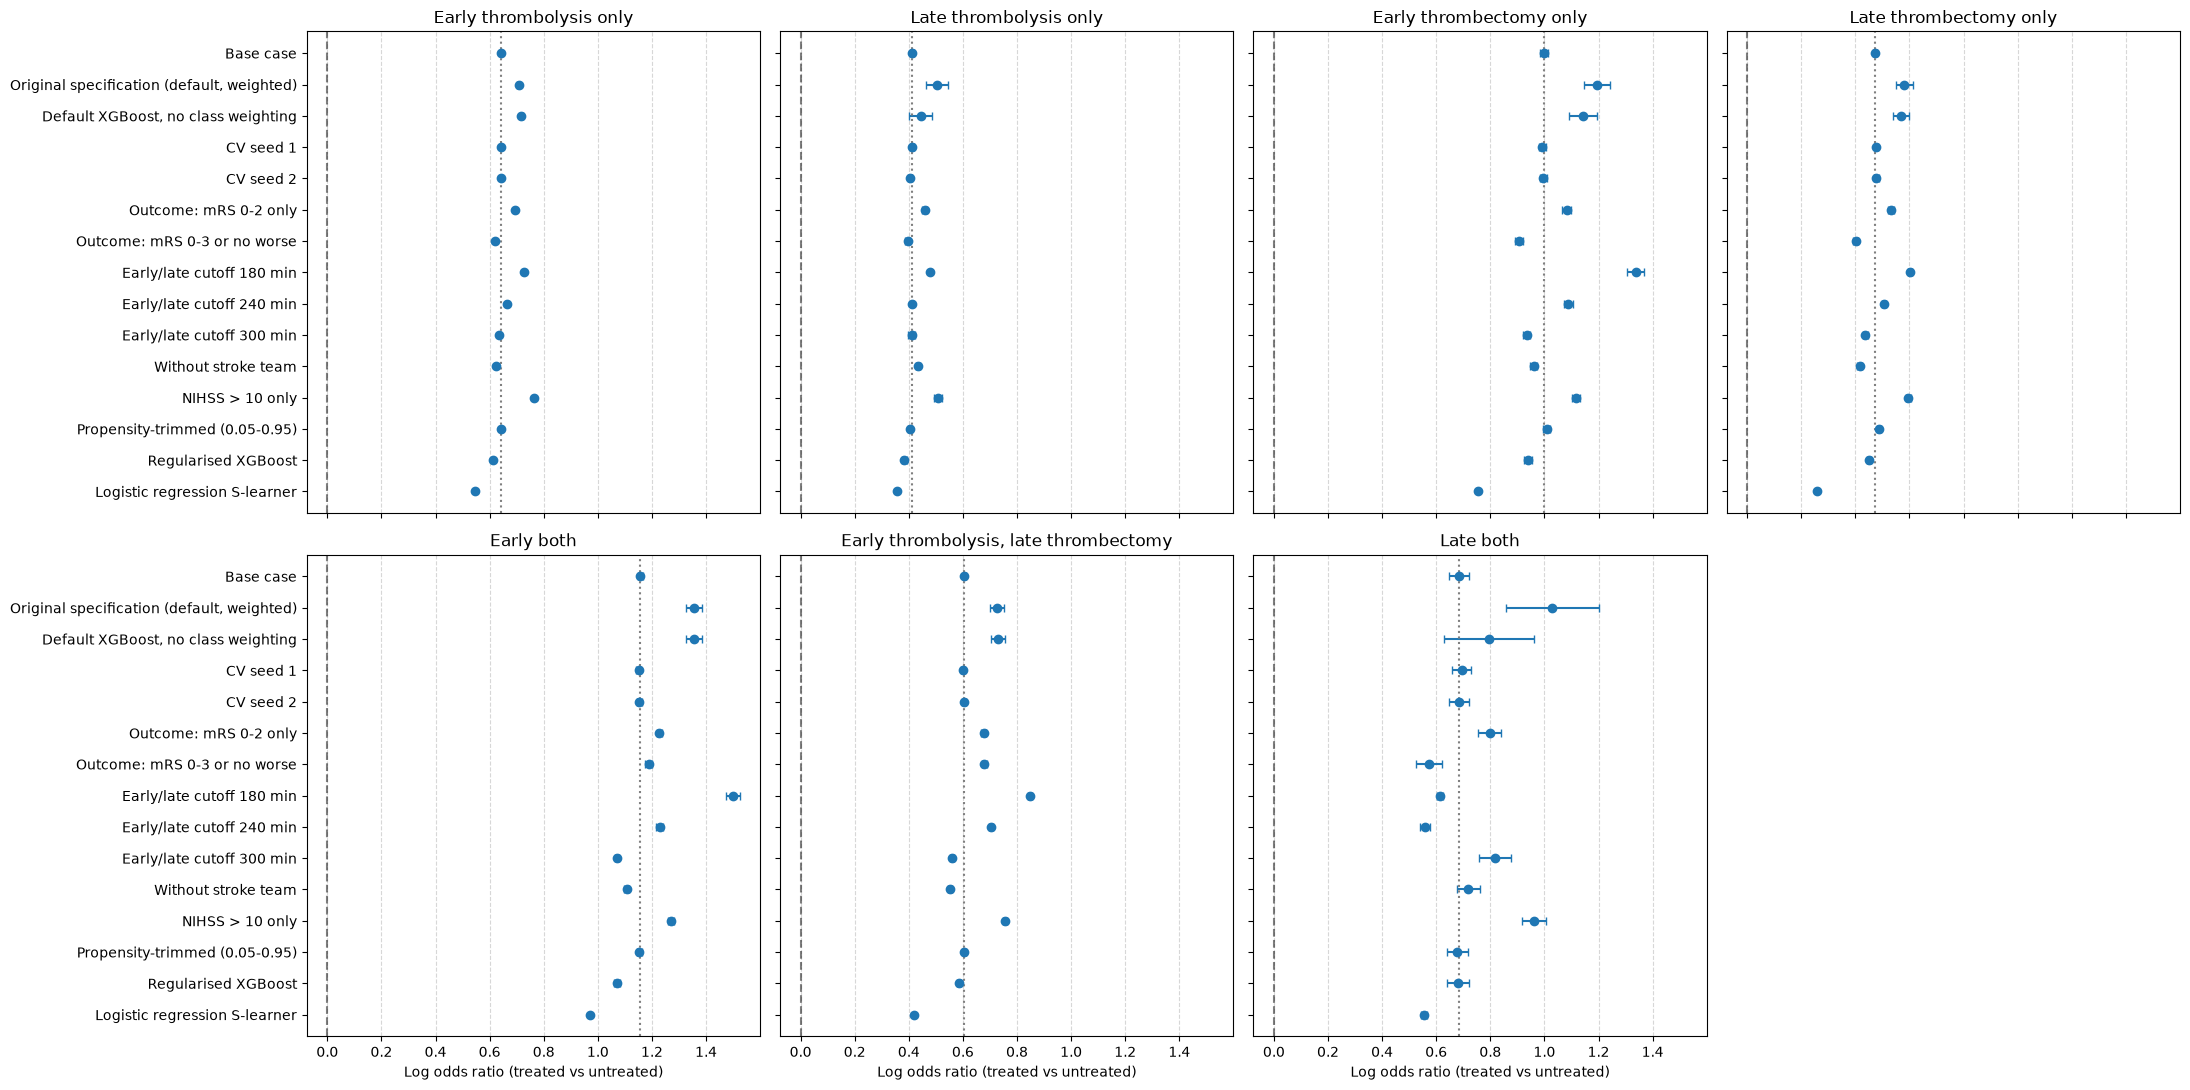

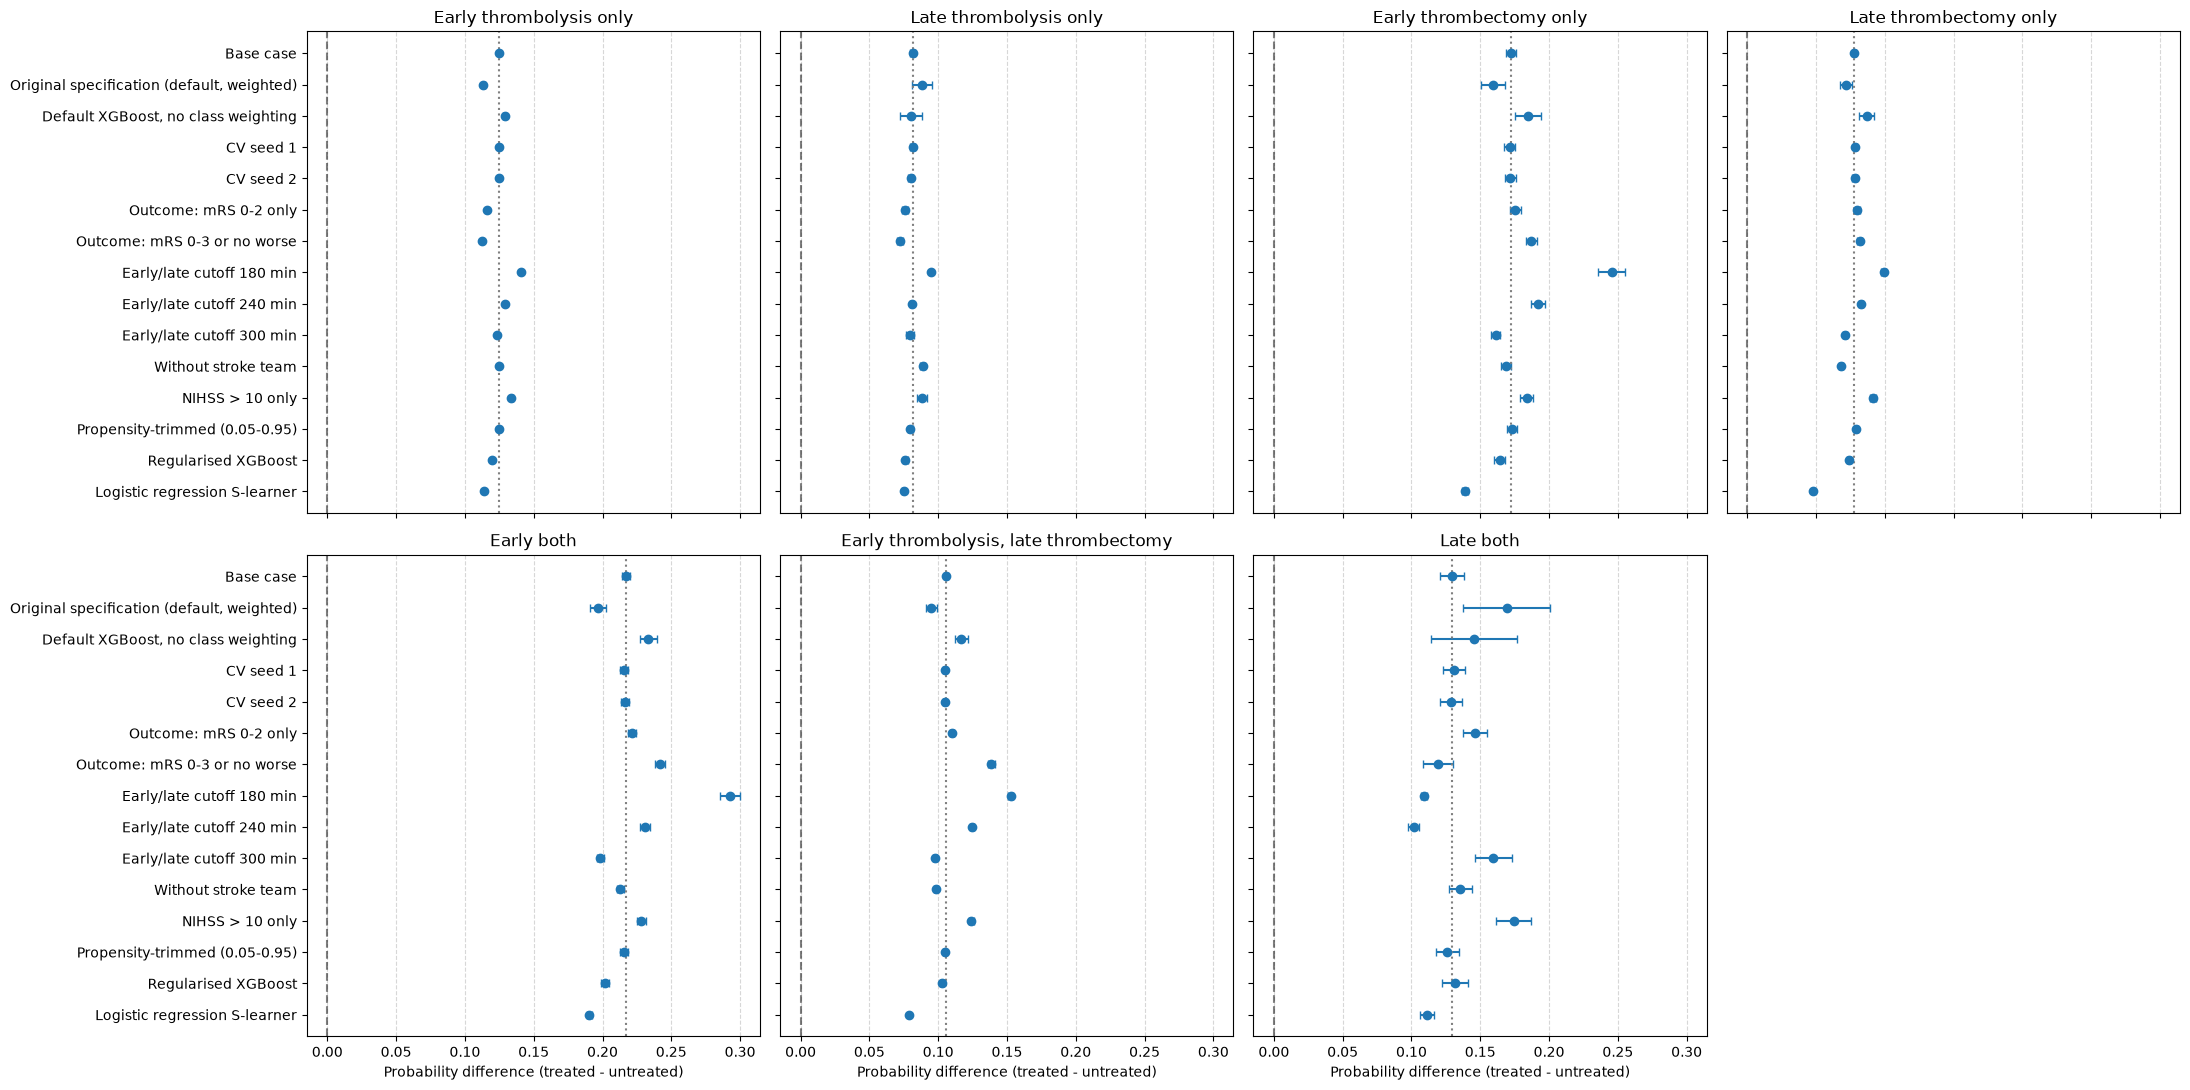

In [36]:
def plot_sensitivity(results, measure, xlabel, filename):
    """One panel per arm: estimate and 95% CI for each scenario; dotted line = base case."""
    res = results[results["measure"] == measure]
    scenarios = list(SCENARIOS)
    y_pos = np.arange(len(scenarios))[::-1]

    fig, axes = plt.subplots(2, 4, figsize=(22, 11), sharex=True, sharey=True)
    for ax, arm in zip(axes.flat, ARM_ORDER):
        arm_res = res[res["treatment_group"] == arm].set_index("scenario").reindex(scenarios)
        ax.errorbar(
            arm_res["mean"], y_pos,
            xerr=[arm_res["mean"] - arm_res["95% CI lower"], arm_res["95% CI upper"] - arm_res["mean"]],
            fmt="o", capsize=3,
        )
        ax.axvline(arm_res.loc["Base case", "mean"], color="grey", linestyle=":")
        ax.axvline(0, color="black", linestyle="--", alpha=0.5)
        ax.set_title(ARM_LABELS[arm].replace("\n", " "))
        ax.grid(axis="x", linestyle="--", alpha=0.5)
    axes[0, 0].set_yticks(y_pos)
    axes[0, 0].set_yticklabels(scenarios)
    for ax in axes[-1, :]:
        ax.set_xlabel(xlabel)
    for ax in axes.flat[len(ARM_ORDER):]:
        ax.axis("off")

    fig.tight_layout()
    fig.savefig(output_path(f"{filename}.png"), dpi=300, bbox_inches="tight")
    plt.show()


plot_sensitivity(sensitivity_results, "log_odds_shift",
                 "Log odds ratio (treated vs untreated)", "sensitivity_log_odds")
plot_sensitivity(sensitivity_results, "prob_shift",
                 "Probability difference (treated - untreated)", "sensitivity_prob")

## D3. Unmeasured confounding: E-values

The E-value (VanderWeele and Ding, 2017) is the minimum strength of association, on the risk-ratio scale, that an unmeasured confounder would need with *both* treatment and outcome, beyond the measured covariates, to fully explain away the estimate. A second E-value is given for the confidence limit closest to the null (1 if the CI already includes the null).

* Good outcome is common here (about 40%), so odds ratios are converted to approximate risk ratios with the square-root approximation RR ~ sqrt(OR), as recommended for common outcomes.
* The arm 'odds ratio' is exp(mean individual log odds shift) from Part B. This approximates, but is not the same as, a marginal odds ratio.
* Interpretation: compare each E-value with the strength of known strong confounders. For example, how strongly do pre-stroke disability or stroke severity relate to both treatment and outcome? A plausible unmeasured factor (such as clinicians' judgement of frailty or imaging findings) at least that strong could explain away estimates with similar or smaller E-values.

In [37]:
def e_value_from_odds_ratio(odds_ratio):
    """E-value for an odds ratio, using RR ~ sqrt(OR) for a common outcome."""
    rr = np.sqrt(np.asarray(odds_ratio, dtype=float))
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))


e_values = np.exp(arm_summary_log_odds[["mean", "95% CI lower", "95% CI upper"]])
e_values.columns = ["OR", "OR 95% CI lower", "OR 95% CI upper"]
e_values["E-value (estimate)"] = e_value_from_odds_ratio(e_values["OR"])

ci_includes_null = (e_values["OR 95% CI lower"] <= 1) & (e_values["OR 95% CI upper"] >= 1)
limit_nearest_null = np.where(e_values["OR"] >= 1, e_values["OR 95% CI lower"], e_values["OR 95% CI upper"])
e_values["E-value (CI limit)"] = np.where(ci_includes_null, 1.0, e_value_from_odds_ratio(limit_nearest_null))

e_values["n"] = arm_summary_log_odds["count"]
e_values.to_csv(output_path("sensitivity_e_values.csv"))
e_values.round(2)

,OR,OR 95% CI lower,OR 95% CI upper,E-value (estimate),E-value (CI limit),n
treatment_group,,,,,,
early_thrombolysis_only,1.90,1.90,1.90,2.10,2.10,27695
late_thrombolysis_only,1.51,1.50,1.52,1.76,1.75,1189
early_thrombectomy_only,2.71,2.68,2.75,2.68,2.66,1107
late_thrombectomy_only,1.60,1.59,1.62,1.85,1.84,1876
early_both,3.18,3.15,3.21,2.96,2.95,2309
early_thrombolysis_late_thrombectomy,1.83,1.82,1.84,2.04,2.03,2714
late_both,1.98,1.91,2.06,2.17,2.11,141


## D4. Further sensitivity analyses to consider (not run here)

* **Bootstrap the whole pipeline.** Current CIs (mean +/- 1.96 SD/sqrt(n) of individual predictions) ignore uncertainty in the fitted models, so they are too narrow. Resample patients with replacement, refit the cross-validated S-learner, and recompute per-arm means (e.g. 100-200 bootstrap samples). Percentile intervals then include model uncertainty. This is computationally heavier (about 5 model fits per replicate).
* **Alternative meta-learners.** S-learners can shrink treatment effects towards zero when the model gives the treatment feature little weight (regularisation bias), especially for small arms (e.g. late both, n ~ 140). Compare with a T-learner (separate models per arm), an X-learner, a doubly robust (DR) learner, or a causal forest (e.g. `econml`). Doubly robust methods also combine the outcome and propensity models, reducing reliance on either one being correct.
* **Placebo / negative-control tests.** (a) Randomly permute treatment arm labels among treated patients and re-estimate: arm differences should disappear. (b) Use a negative-control outcome, one treatment cannot plausibly affect but that shares confounders (e.g. a pre-treatment characteristic not used as a feature). A non-zero 'effect' indicates residual confounding.
* **Instrumental variable analysis.** Use between-hospital variation in treatment rates (e.g. team thrombolysis or thrombectomy rate) as an instrument, which addresses unmeasured patient-level confounding by indication, under its own assumptions.
* **Missing data.** Compare XGBoost's native handling of missing values with multiple imputation, and with complete-case analysis.
* **Selection criteria.** Vary the arrival window (e.g. 4 hours), the severity threshold, and whether patients with perfusion imaging are included.
* **Calibration.** Plot observed vs predicted outcome by decile for each fold and scenario. Probability-scale effects are only as good as the calibration of the outcome model.